# Домашнее задание № 1: рекомендации top-10

Шуминов Эзра Самирович · группа Б05-305д

Сравниваются пять самостоятельно реализованных моделей на отзывах Amazon Digital Music. Параметры выбираются по validation, итоговые метрики считаются на test.

[Данные](#data) · [EDA](#eda) · [Протокол](#protocol) · [Модели](#models) · [Сравнение](#comparison) · [Выводы](#conclusions)

### Запуск

Из корня проекта с Python 3.12:

```bash
python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
export PYTHONHASHSEED=42
python -m nbconvert --to notebook --execute --inplace experiments.ipynb --ExecutePreprocessor.timeout=-1
```

Данные загружаются автоматически в `.local/data` или `RECSYS_DATA_DIR`. Если загрузка недоступна, положите туда [архив Digital Music 5-core](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Digital_Music_5.json.gz); SHA-256 проверяется загрузчиком. Для запуска в Jupyter выберите ядро `.venv` и выполните все ячейки с новым ядром. `RECOMPUTE_ALL = True` в следующей ячейке отключает кеш обучения. Полный CPU-прогон занимает около 50 минут и до 2,4 GiB памяти рабочего процесса.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "configs" / "experiment.json").is_file():
    raise RuntimeError("Запустите notebook из корня проекта.")

from utils.reproducibility import (
    configure_reproducibility,
    load_config,
    resolve_data_dir,
    save_environment,
)

# True: принудительно повторить обучение, подбор и финальные refit.
RECOMPUTE_ALL = False
config = load_config()
if RECOMPUTE_ALL:
    config["runtime"]["reuse_model_cache"] = False
generators = configure_reproducibility(config)
environment_path = save_environment(config)

print(f"Python: {sys.version.split()[0]}")
print(f"Seed: {config['seed']}; device: {config['runtime']['device']}")
print(f"CPU threads: {config['runtime']['cpu_threads']}")
print(f"Stage: {config['stage']}")
print(f"Environment report: {environment_path.relative_to(PROJECT_ROOT)}")
data_directory = resolve_data_dir(config)
data_directory_label = (
    data_directory.relative_to(PROJECT_ROOT)
    if data_directory.is_relative_to(PROJECT_ROOT)
    else "каталог из RECSYS_DATA_DIR"
)
print(f"Data directory: {data_directory_label}")
print(f"Reuse verified model cache: {config['runtime']['reuse_model_cache']}")

Python: 3.12.3
Seed: 42; device: cpu
CPU threads: 1
Stage: notebook_finalized
Environment report: results/environment.json
Data directory: .local/data
Reuse verified model cache: True


In [2]:
import importlib
from importlib import metadata

import numpy as np
import scipy
import pandas as pd
import torch
import matplotlib
import seaborn as sns

for module in (
    "models.base", "models.item_knn", "models.ials", "models.ease",
    "models.fm", "models.custom_ials", "utils.data", "utils.splitting",
    "utils.features", "utils.evaluation",
):
    importlib.import_module(module)

packages = [
    "numpy", "scipy", "pandas", "torch", "matplotlib", "seaborn",
    "jupyterlab", "ipykernel", "nbformat", "nbclient", "nbconvert",
    "threadpoolctl", "psutil",
]
pd.DataFrame({"package": packages, "version": [metadata.version(p) for p in packages]})

,package,version
0,numpy,2.3.1
1,scipy,1.16.0
2,pandas,2.3.0
3,torch,2.9.0+cpu
4,matplotlib,3.10.3
5,seaborn,0.13.2
6,jupyterlab,4.4.7
7,ipykernel,6.30.1
8,nbformat,5.10.4
9,nbclient,0.10.2


### Проверка seed

Одинаковый seed должен давать одинаковые последовательности новых генераторов.

In [3]:
numpy_first = np.random.default_rng(config["seed"]).random(5)
numpy_repeat = np.random.default_rng(config["seed"]).random(5)
assert np.array_equal(numpy_first, numpy_repeat)

torch_first = torch.rand(5, generator=torch.Generator().manual_seed(config["seed"]))
torch_repeat = torch.rand(5, generator=torch.Generator().manual_seed(config["seed"]))
assert torch.equal(torch_first, torch_repeat)
assert torch.get_num_threads() == config["runtime"]["cpu_threads"]
assert torch.are_deterministic_algorithms_enabled()

print("Импорты, seed NumPy/PyTorch и число потоков проверены.")

Импорты, seed NumPy/PyTorch и число потоков проверены.


<a id="data"></a>

## 1. Загрузка и описание данных

Источник — [Amazon Review Data (2018), Digital Music, 5-core](https://nijianmo.github.io/amazon/index.html), [архив](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Digital_Music_5.json.gz). Рекомендуются товары с ID `asin`, ранее не встречавшиеся пользователю. Взаимодействие — отзыв, а не прослушивание. Положительным считаем отзыв с оценкой ≥4. Датасет не использовался на семинарах; готовый 5-core смещён в сторону активных пользователей и товаров.

### Поля

| Поле | Смысл |
|---|---|
| `reviewerID` | Пользователь |
| `asin` | Товар |
| `overall` | Оценка 1–5 |
| `unixReviewTime` | Время отзыва (Unix seconds) |
| `source_line` | Номер строки, добавленный загрузчиком для разрешения дублей |

Текст отзыва и будущие сведения о товаре в модель не подаются. Публикуются агрегаты без исходных ID и строк отзывов.

In [4]:
from utils.data import obtain_reviews, save_dataset_reports, summarize_reviews

raw_reviews, dataset_manifest = obtain_reviews(config)
raw_summary = summarize_reviews(raw_reviews, config)
save_dataset_reports(dataset_manifest, raw_summary, config)

assert dataset_manifest["sha256"] == config["dataset"]["sha256"]
assert raw_reviews["source_line"].is_unique

pd.DataFrame({"value": {
    "archive": dataset_manifest["filename"],
    "downloaded_at_utc": dataset_manifest["downloaded_at_utc"],
    "size_bytes": dataset_manifest["size_bytes"],
    "sha256": dataset_manifest["sha256"],
    "download_url": dataset_manifest["requested_url"],
}})

,value
archive,Digital_Music_5.json.gz
downloaded_at_utc,2026-10-26T12:43:33.936628+00:00
size_bytes,19457656
sha256,703f60f74bf1967a75cbb3033532172eeb21139d4df04e...
download_url,https://mcauleylab.ucsd.edu/public_datasets/da...


In [5]:
pd.DataFrame({"value": {
    "raw_interactions": raw_summary["n_interactions"],
    "raw_users": raw_summary["n_users"],
    "raw_items": raw_summary["n_items"],
    "first_review_utc": raw_summary["timestamp_min_utc"],
    "last_review_utc": raw_summary["timestamp_max_utc"],
    "invalid_ratings": raw_summary["invalid_rating_rows"],
    "invalid_timestamps": raw_summary["invalid_timestamp_rows"],
}})

,value
raw_interactions,169781
raw_users,16566
raw_items,11797
first_review_utc,1998-07-09T00:00:00+00:00
last_review_utc,2018-09-26T00:00:00+00:00
invalid_ratings,0
invalid_timestamps,0


In [6]:
pd.DataFrame.from_dict(raw_summary["required_fields"], orient="index")

,source_field,non_null_rows,missing_rows,dtype
user_id,reviewerID,169781,0,object
item_id,asin,169781,0,object
rating,overall,169781,0,float64
timestamp,unixReviewTime,169781,0,int64


### Оценки и метаданные исходного файла

Ниже — общие свойства архива; настройка моделей проводится по train/validation.

In [7]:
pd.DataFrame([
    {"rating": int(rating), "n_reviews": count}
    for rating, count in raw_summary["rating_distribution"].items()
])

,rating,n_reviews
0,1,2192
1,2,1812
2,3,6792
3,4,23143
4,5,135842


In [8]:
pd.DataFrame([
    {"field": field, "non_null_rows": count, "total_rows": len(raw_reviews)}
    for field, count in raw_summary["optional_field_non_null_rows"].items()
])

,field,non_null_rows,total_rows
0,image,182,169781
1,reviewText,169623,169781
2,reviewTime,169781,169781
3,reviewerName,169776,169781
4,style,157989,169781
5,summary,169745,169781
6,verified,169781,169781
7,vote,7611,169781


### Доступность признаков

ID нужны всем методам; оценка и время — для релевантности, временного разбиения и нового таргета. FM дополнительно использует прошлые счётчики, средние оценки, доли положительных отзывов и возраст истории объекта. Для обучающего события признаки считаются строго до его timestamp; вся группа с тем же временем исключается. Текущие оценка и текст не являются признаками.

<a id="eda"></a>

## 2. EDA и подготовка

### Очистка

Удаляются строки с пустыми ID, ошибочным временем или оценкой вне 1–5. Затем удаляются точные дубли. Для каждой пары пользователь–товар остаётся самый ранний отзыв; равенство времени разрешает `source_line`. Низкие оценки сохраняются: они нужны для истории и маски просмотренных товаров. Дополнительный k-core и подвыборка не применяются.

In [9]:
from utils.cleaning import clean_reviews, save_cleaned_reviews, validate_cleaned_reviews

cleaned_reviews, clean_summary = clean_reviews(raw_reviews, config)
cleaned_path = save_cleaned_reviews(cleaned_reviews, clean_summary, config)
size_checks = validate_cleaned_reviews(cleaned_reviews, config)

assert all(check["passed"] for check in size_checks.values())
assert not cleaned_reviews.duplicated(["user_id", "item_id"]).any()
assert str(cleaned_reviews["timestamp"].dt.tz) == "UTC"
print(f"Локальный очищенный файл: {cleaned_path.name}")
print(f"SHA-256 содержимого: {clean_summary['content_sha256']}")

Локальный очищенный файл: cleaned_interactions.csv.gz
SHA-256 содержимого: 7214299563d39665fbced9981a8e78c257986d466c5d6b7b78730702378ef9f2


### Аудит очистки

Этапы удаления идут последовательно; `source_line` фиксирует выбор при совпадении времени.

In [10]:
pd.DataFrame(clean_summary["audit"])

,stage,input_rows,output_rows,removed_rows,n_users,n_items
0,input,169781,169781,0,16566,11797
1,drop_missing_ids,169781,169781,0,16566,11797
2,drop_invalid_timestamps,169781,169781,0,16566,11797
3,drop_invalid_ratings,169781,169781,0,16566,11797
4,drop_exact_duplicates,169781,146158,23623,16566,11797
5,keep_earliest_pair,146158,145292,866,16566,11797


In [11]:
pd.DataFrame([
    {"measure": "interactions", "raw": raw_summary["n_interactions"], "cleaned": clean_summary["n_interactions"]},
    {"measure": "users", "raw": raw_summary["n_users"], "cleaned": clean_summary["n_users"]},
    {"measure": "items", "raw": raw_summary["n_items"], "cleaned": clean_summary["n_items"]},
])

,measure,raw,cleaned
0,interactions,169781,145292
1,users,16566,16566
2,items,11797,11797


### Размер выборки

Ограничения задания проверяются после очистки, а не по размеру исходного архива.

In [12]:
pd.DataFrame.from_dict(clean_summary["constraints"], orient="index")

,actual,min,max,passed
interactions,145292,100000,2000000.0,True
users,16566,1000,NaN,True
items,11797,1000,NaN,True


In [13]:
assert (
    clean_summary["n_positive_interactions"] + clean_summary["n_low_rating_interactions"]
    == clean_summary["n_interactions"]
)
pd.DataFrame({"value": {
    "positive_rating_ge_4": clean_summary["n_positive_interactions"],
    "low_rating_lt_4_kept": clean_summary["n_low_rating_interactions"],
    "first_review_utc": clean_summary["timestamp_min_utc"],
    "last_review_utc": clean_summary["timestamp_max_utc"],
    "all_size_constraints_passed": clean_summary["cleaned_constraints_verified"],
}})

,value
positive_rating_ge_4,135889
low_rating_lt_4_kept,9403
first_review_utc,1998-07-09T00:00:00+00:00
last_review_utc,2018-09-26T00:00:00+00:00
all_size_constraints_passed,True


In [14]:
pd.DataFrame.from_dict(clean_summary["dtypes"], orient="index", columns=["dtype"])

,dtype
user_id,string
item_id,string
rating,float64
timestamp,"datetime64[ns, UTC]"
source_line,int64


После очистки остаётся 145 292 взаимодействия, 16 566 пользователей и 11 797 товаров. Данные и индивидуальные строки хранятся локально; в `results/` записаны только агрегаты и контрольные суммы.

### EDA на train

Распределения ниже построены только по событиям до `T1`. Метапризнаки рассчитываются по истории до каждого события; снимок на `T1` отдельно описывает состояние к началу validation.

In [15]:
%matplotlib inline
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from utils.eda import build_eda_profile, plot_eda, save_eda_tables
from utils.splitting import temporal_split

eda_periods, eda_split_summary = temporal_split(cleaned_reviews, config)
eda_train = eda_periods["train"]
eda_profile = build_eda_profile(eda_train, config)
eda_results_dir = save_eda_tables(eda_profile, config)
eda_figures = plot_eda(eda_profile, eda_results_dir / "figures")
eda = eda_profile["summary"]
assert eda["analyzed_period"] == "train"
assert not eda["test_rating_statistics_included"]
print(f"EDA train: {eda['n_interactions']:,} отзывов, {eda['n_users']:,} пользователей, {eda['n_items']:,} объектов.")
print(f"Все события раньше {eda['cutoff_utc']}.")

EDA train: 116,209 отзывов, 15,273 пользователей, 11,611 объектов.
Все события раньше 2016-06-16T00:00:00+00:00.


#### Пропуски

Необязательные поля не влияют на сохранение отзыва: признаки FM строятся из наблюдаемой истории.

In [16]:
renamed_raw = raw_reviews.rename(columns={source: target for target, source in config["dataset"]["fields"].items()})
missing_comparison = pd.DataFrame({
    "missing_raw": renamed_raw.isna().sum(),
    "missing_cleaned": cleaned_reviews.isna().sum(),
    "missing_train": eda_train.isna().sum(),
    "train_missing_percent": eda_train.isna().mean() * 100,
}).rename_axis("field")
missing_comparison

,missing_raw,missing_cleaned,missing_train,train_missing_percent
field,,,,
rating,0,0,0,0.000000
vote,162170,138595,109918,94.586478
verified,0,0,0,0.000000
reviewTime,0,0,0,0.000000
user_id,0,0,0,0.000000
item_id,0,0,0,0.000000
style,11792,9576,7925,6.819609
reviewerName,5,4,4,0.003442
reviewText,158,146,46,0.039584


Самый ранний отзыв определяет оценку пары. Оценки 1–3 остаются в истории и в обучающих данных FM.

#### Активность и популярность

Логарифмические оси показывают длинные хвосты; графики содержат только агрегаты.

In [17]:
eda_profile["tables"]["activity_quantiles"].round(2)

,statistic,users_all_reviews,items_all_reviews,users_positive_reviews,items_positive_reviews
0,count,15273.00,11611.00,15273.00,11611.00
1,mean,7.61,10.01,7.09,9.32
2,std,9.09,13.84,7.84,12.97
3,min,1.00,1.00,0.00,0.00
4,25%,4.00,4.00,4.00,4.00
5,50%,5.00,6.00,5.00,6.00
6,75%,8.00,11.00,8.00,10.00
7,90%,14.00,19.00,13.00,18.00
8,95%,20.00,28.00,18.00,26.00
9,99%,40.00,64.00,37.00,61.00


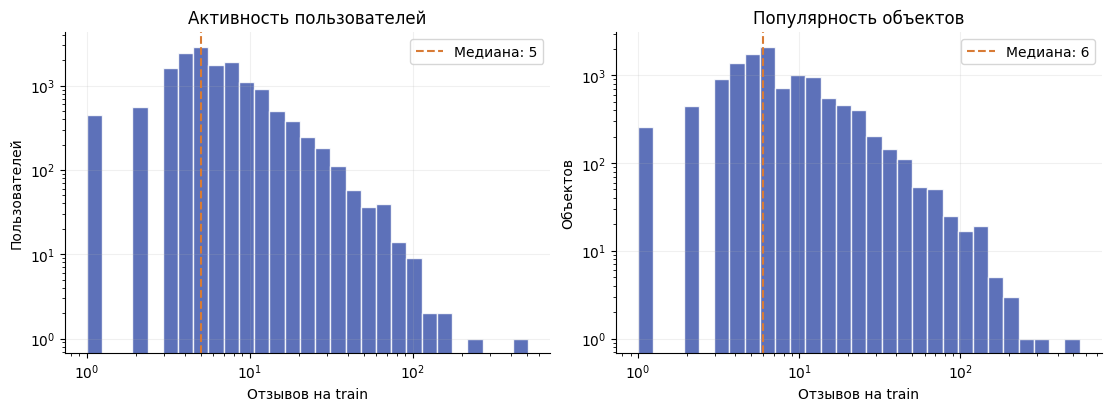

In [18]:
display(eda_figures["01_activity_popularity"])

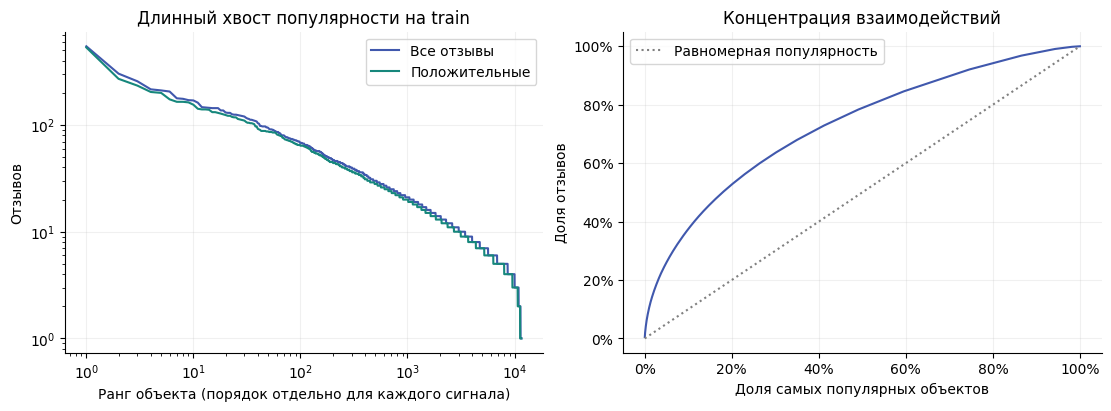

In [19]:
display(eda_figures["02_popularity_concentration"])

In [20]:
display(Markdown(
    f"Медианная история пользователя — **{eda['user_history_median']:.0f}** отзывов, "
    f"объекта — **{eda['item_history_median']:.0f}**; максимумы — "
    f"**{eda['user_history_max']}** и **{eda['item_history_max']}**. "
    f"Самые популярные 1% объектов ({eda['top_1pct_items_count']} шт.) собирают "
    f"**{eda['top_1pct_items_interaction_fraction']:.2%}** отзывов train. "
    "Редкие истории и концентрация взаимодействий мотивируют регуляризацию "
    "и проверку качества на полном каталоге; лидер модели из этих распределений не следует."
))

Медианная история пользователя — **5** отзывов, объекта — **6**; максимумы — **511** и **547**. Самые популярные 1% объектов (117 шт.) собирают **10.53%** отзывов train. Редкие истории и концентрация взаимодействий мотивируют регуляризацию и проверку качества на полном каталоге; лидер модели из этих распределений не следует.

#### Положительная история

Порог положительного отзыва — `rating >= 4`. Пользователи без положительных отзывов тоже входят в распределение.

In [21]:
eda_profile["tables"]["short_histories"].assign(percent=lambda table: table["fraction_users"] * 100)

,max_reviews,n_users,fraction_users,percent
0,1,443,0.029005,2.900543
1,3,2623,0.171741,17.174098
2,5,7998,0.523669,52.366922


In [22]:
eda_profile["tables"]["ratings"].assign(percent=lambda table: table["fraction"] * 100)

,rating,n_reviews,fraction,percent
0,1,1581,0.013605,1.360480
1,2,1358,0.011686,1.168584
2,3,5027,0.043258,4.325827
3,4,16434,0.141418,14.141762
4,5,91809,0.790033,79.003347


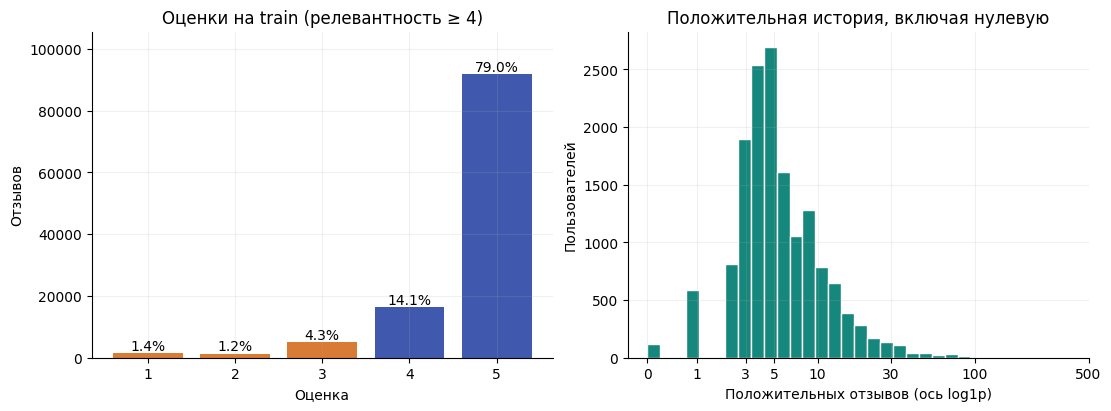

Не более трёх отзывов имеют **17.17%** пользователей train. Без положительной истории — **120** пользователей (**0.79%**). Доля положительных отзывов — **93.15%**. Ненаблюдаемая пара не означает достоверную отрицательную оценку: это ограничение iALS и семплирования отрицательных примеров FM.

In [23]:
display(eda_figures["03_ratings_positive_history"])
display(Markdown(
    f"Не более трёх отзывов имеют **{eda['fraction_users_with_at_most_3_reviews']:.2%}** пользователей train. "
    f"Без положительной истории — **{eda['n_users_without_positive_history']}** пользователей "
    f"(**{eda['fraction_users_without_positive_history']:.2%}**). "
    f"Доля положительных отзывов — **{eda['positive_fraction']:.2%}**. "
    "Ненаблюдаемая пара не означает достоверную отрицательную оценку: "
    "это ограничение iALS и семплирования отрицательных примеров FM."
))

#### Разреженность

$S=1-\mathrm{nnz}/(n_{users}n_{items})$. Знаменатель одинаков для всех отзывов и только положительных пар.

In [24]:
eda_profile["tables"]["sparsity"].assign(
    sparsity_percent=lambda table: table["sparsity"] * 100
)[["signal", "n_users", "n_items", "possible_pairs", "nnz", "sparsity_percent"]]

,signal,n_users,n_items,possible_pairs,nnz,sparsity_percent
0,all_reviews,15273,11611,177334803,116209,99.934469
1,positive_reviews,15273,11611,177334803,108243,99.938961


Из-за разреженности взаимодействия хранятся в sparse-матрицах. Для плотной матрицы EASE отдельно проверяется память.

#### Динамика train

Показаны месяцы до `T1`. Последний месяц неполный; рост числа отзывов сам по себе не объясняет его причину.

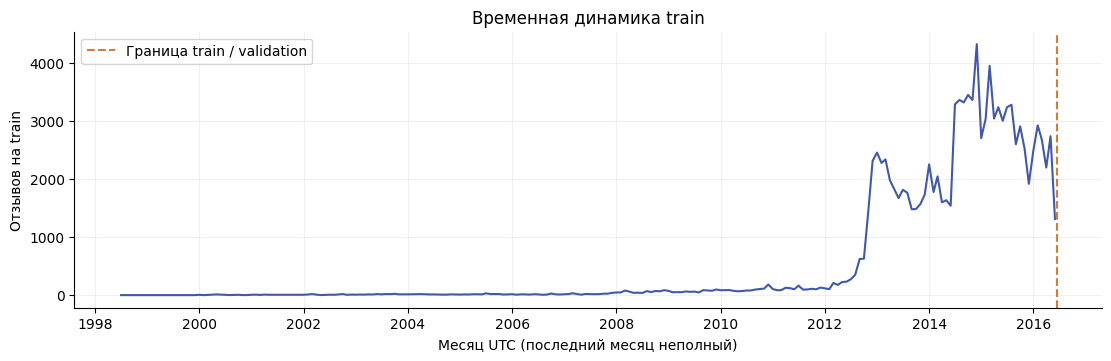

In [25]:
display(eda_figures["04_train_monthly_activity"])

#### Исторические признаки

Перед каждой timestamp-группой считаются `log1p` числа отзывов, средняя оценка, доля положительных и признак пустой истории для пользователя и товара. Для товара также считается время с первого наблюдаемого отзыва. При пустой истории средняя оценка равна 3, остальные агрегаты — 0. Это заранее заданные значения, а не сведения из будущего.

In [26]:
feature_summary = eda_profile["tables"]["metadata_summary"]
feature_summary.loc[feature_summary["context"].eq("before_training_event")].drop(columns="context").round(4)

,entity,feature,n_values,missing_values,zero_values,mean,min,median,p95,p99,max
0,user,log1p_review_count,116209,0,48428,0.9946,0.0,0.6931,3.1355,4.2767,6.2364
1,user,mean_rating,116209,0,0,3.9689,1.0,4.0000,5.0000,5.0000,5.0000
2,user,positive_fraction,116209,0,49727,0.5408,0.0,0.8421,1.0000,1.0000,1.0000
3,user,empty_history,116209,0,67781,0.4167,0.0,0.0000,1.0000,1.0000,1.0000
8,item,log1p_review_count,116209,0,12150,1.9199,0.0,1.7918,4.0254,4.9127,6.3026
9,item,mean_rating,116209,0,0,4.4816,1.0,4.7500,5.0000,5.0000,5.0000
10,item,positive_fraction,116209,0,13249,0.8287,0.0,1.0000,1.0000,1.0000,1.0000
11,item,log1p_observed_age_days,116209,0,12150,5.3014,0.0,6.0868,7.6111,7.9861,8.7475
12,item,empty_history,116209,0,104059,0.1046,0.0,0.0000,1.0000,1.0000,1.0000


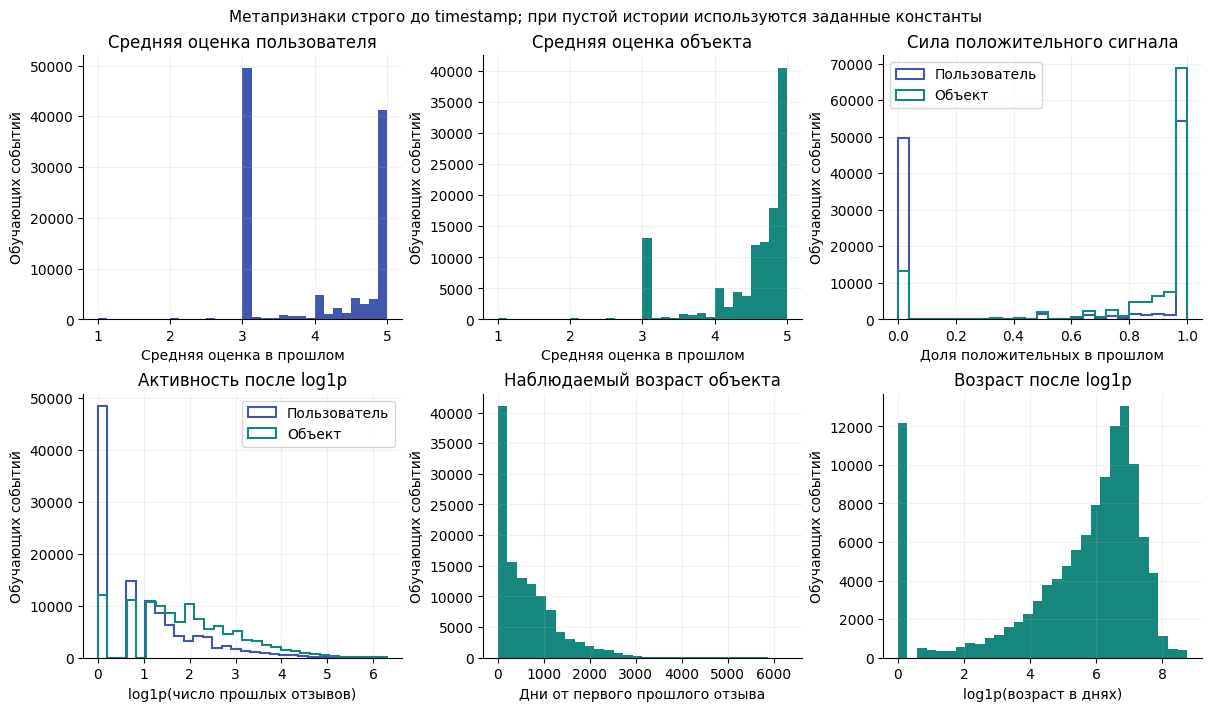

In [27]:
display(eda_figures["05_historical_metadata"])

In [28]:
display(Markdown(
    f"Без прошлой истории пользователя находятся **{eda['training_events_without_prior_user_history']:,}** "
    f"обучающих событий (**{eda['fraction_events_without_prior_user_history']:.2%}**), "
    f"объекта — **{eda['training_events_without_prior_item_history']:,}** "
    f"(**{eda['fraction_events_without_prior_item_history']:.2%}**). "
    f"У **{eda['fraction_events_at_utc_midnight']:.0%}** событий train timestamp попадает "
    "на 00:00 UTC; порядок внутри этой временной метки неизвестен. "
    "Поэтому несколько первых отзывов пользователя с одним timestamp одновременно "
    "имеют пустую прошлую историю. Индикаторы пустой истории нужны и при готовом 5-core."
))

Без прошлой истории пользователя находятся **48,428** обучающих событий (**41.67%**), объекта — **12,150** (**10.46%**). У **100%** событий train timestamp попадает на 00:00 UTC; порядок внутри этой временной метки неизвестен. Поэтому несколько первых отзывов пользователя с одним timestamp одновременно имеют пустую прошлую историю. Индикаторы пустой истории нужны и при готовом 5-core.

Следующая таблица показывает снимок истории на `T1`. Он нужен для рекомендаций на validation, но не подставляется в более ранние обучающие события.

In [29]:
feature_summary.loc[feature_summary["context"].eq("at_validation_cutoff")].drop(columns="context").round(4)

,entity,feature,n_values,missing_values,zero_values,mean,min,median,p95,p99,max
4,user,log1p_review_count,15273,0,0,1.9462,0.6931,1.7918,3.0445,3.7136,6.2383
5,user,mean_rating,15273,0,0,4.7047,1.0000,5.0000,5.0000,5.0000,5.0000
6,user,positive_fraction,15273,0,120,0.9373,0.0000,1.0000,1.0000,1.0000,1.0000
7,user,empty_history,15273,0,15273,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
13,item,log1p_review_count,11611,0,0,2.1127,0.6931,1.9459,3.3673,4.1744,6.3063
14,item,mean_rating,11611,0,0,4.6856,1.0000,4.8000,5.0000,5.0000,5.0000
15,item,positive_fraction,11611,0,31,0.9319,0.0000,1.0000,1.0000,1.0000,1.0000
16,item,log1p_observed_age_days,11611,0,0,6.9214,1.0986,7.0901,7.9143,8.4559,8.7877
17,item,empty_history,11611,0,11611,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Счётчики и возраст преобразуются через `log1p`; нормировка FM обучается только на train. Готовый 5-core не гарантирует пяти событий в каждом временном периоде. Отзывы отражают неполный интерес пользователя, а одинаковый timestamp не задаёт порядок внутри группы.

<a id="protocol"></a>

## 3. Протокол оценки

### Разбиение и метрики

Для каждого пользователя выдаём 10 ранее не оценённых товаров. Релевантность — будущий отзыв с `rating >= 4`. Основная метрика **NDCG@10** учитывает место попадания, дополнительная **Recall@10** — долю найденных релевантных товаров.

Границы общие для всех пользователей и выбраны по накопленному числу событий около 80% и 90%, без оценки качества моделей: `train: t<T1`, `validation: T1≤t<T2`, `test: t≥T2`. Одинаковые timestamp не разделяются. Получились `T1=2016-06-16`, `T2=2017-02-02` (UTC). Параметры подбираются по validation, test открывается после выбора.

In [30]:
from utils.splitting import save_split_report, temporal_split

periods, split_summary = temporal_split(cleaned_reviews, config)
train_reviews = periods["train"]
validation_reviews = periods["validation"]
test_reviews = periods["test"]
local_membership_path = save_split_report(periods, split_summary, config)

print(f"T1 (validation start, UTC): {split_summary['validation_start_utc']}")
print(f"T2 (test start, UTC): {split_summary['test_start_utc']}")
print(f"Local membership: {local_membership_path.name}")
pd.DataFrame.from_dict(split_summary["periods"], orient="index").assign(
    percent=lambda table: table["fraction"] * 100
)[["n_interactions", "percent", "timestamp_min_utc", "timestamp_max_utc"]]

T1 (validation start, UTC): 2016-06-16T00:00:00+00:00
T2 (test start, UTC): 2017-02-02T00:00:00+00:00
Local membership: temporal_membership.csv.gz


,n_interactions,percent,timestamp_min_utc,timestamp_max_utc
train,116209,79.983069,1998-07-09T00:00:00+00:00,2016-06-15T00:00:00+00:00
validation,14578,10.033588,2016-06-16T00:00:00+00:00,2017-02-01T00:00:00+00:00
test,14505,9.983344,2017-02-02T00:00:00+00:00,2018-09-26T00:00:00+00:00


In [31]:
assert all(split_summary["checks"].values())
assert sum(len(part) for part in periods.values()) == len(cleaned_reviews)
assert split_summary["cleaned_content_sha256"] == clean_summary["content_sha256"]
assert config["split"]["boundary_source_content_sha256"] == clean_summary["content_sha256"]
pd.DataFrame.from_dict(split_summary["checks"], orient="index", columns=["passed"])

,passed
periods_nonempty,True
all_rows_assigned_once,True
strict_temporal_order,True
equal_timestamps_stay_together,True


### История и кандидаты

На validation доступна история до `T1`; для test модель переобучается на train+validation до `T2`. Внутри отложенного периода история не обновляется. Каталог состоит из товаров с положительной обучающей историей; из него удаляются **все** ранее оценённые пользователем товары, включая оценки 1–3. Пользователи и кандидаты фиксируются для всех моделей одинаково.

### Общий validation-набор

Пусть $H$ — доступная история, $I_H$ — товары с положительным отзывом в ней, $Seen_H(u)$ — все известные пользователю товары. Тогда кандидаты $C_H(u)=I_H\setminus Seen_H(u)$, а релевантные кандидаты $G_Q(u)$ — положительные отзывы будущего периода $Q$ внутри $C_H(u)$. Ранжируется весь каталог без семплирования кандидатов.

Оцениваются пользователи с положительной историей, хотя бы одним релевантным кандидатом и минимум 10 кандидатами. Холодные пользователи и товары учитываются в отдельном отчёте.

In [32]:
from utils.evaluation import (
    build_evaluation_stage, recommend_top_k, save_evaluation_stage,
    validate_recommendations,
)

validation_stage = build_evaluation_stage(periods, config, period="validation")
validation_protocol_path = save_evaluation_stage(validation_stage, config)
validation_context = validation_stage.context
validation_report = validation_stage.report

assert not validation_report["test_labels_used"]
assert len(validation_stage.user_indices) == validation_report["n_evaluation_users"]
assert validation_stage.ground_truth.nnz == validation_report["n_relevant_pairs"]
pd.DataFrame({"value": {
    "history_users": validation_report["history_n_users"],
    "history_items": validation_report["history_n_items"],
    "warm_history_users": validation_report["n_warm_history_users"],
    "catalog_items": validation_report["n_catalog_items"],
    "common_evaluation_users": validation_report["n_evaluation_users"],
    "relevant_pairs": validation_report["n_relevant_pairs"],
    "mean_candidates": validation_report["mean_candidates_per_evaluation_user"],
    "min_candidates": validation_report["min_candidates_per_evaluation_user"],
}})

,value
history_users,15273.000000
history_items,11611.000000
warm_history_users,15153.000000
catalog_items,11580.000000
common_evaluation_users,2726.000000
relevant_pairs,8005.000000
mean_candidates,11572.267792
min_candidates,11069.000000


In [33]:
pd.DataFrame([
    {"matrix": "R_H: positive history", "n_users": validation_context.positive.shape[0],
     "n_items": validation_context.positive.shape[1], "nnz": validation_context.positive.nnz},
    {"matrix": "Seen_H: all known interactions", "n_users": validation_context.seen.shape[0],
     "n_items": validation_context.seen.shape[1], "nnz": validation_context.seen.nnz},
    {"matrix": "Ground truth: relevant candidates", "n_users": validation_stage.ground_truth.shape[0],
     "n_items": validation_stage.ground_truth.shape[1], "nnz": validation_stage.ground_truth.nnz},
])

,matrix,n_users,n_items,nnz
0,R_H: positive history,15273,11611,108243
1,Seen_H: all known interactions,15273,11611,116209
2,Ground truth: relevant candidates,15273,11611,8005


### Холодный старт

Таблица показывает, сколько пользователей и положительных событий исключено из общей warm-start оценки.

In [34]:
pd.DataFrame(validation_report["user_audit"])

,rule,remaining_users
0,held_out_users,3814
1,warm_user,3080
2,enough_candidates,3080
3,has_relevant_candidate,2726


In [35]:
pd.DataFrame(validation_report["positive_event_audit"])

,rule,input_positive_events,removed_positive_events,remaining_positive_events
0,warm_user,13886,5090,8796
1,item_in_catalog,8796,791,8005
2,exclude_all_seen,8005,0,8005
3,enough_candidates,8005,0,8005


In [36]:
pd.DataFrame.from_dict(validation_report["cold_start"], orient="index", columns=["value"])

,value
cold_user_ids,734.000000
fraction_held_out_user_ids,0.192449
new_user_ids,699.000000
known_users_without_positive_history,35.000000
out_of_catalog_item_ids,179.000000
fraction_held_out_item_ids,0.027572
new_item_ids,163.000000
known_items_without_positive_history,16.000000
positive_events_with_cold_user,5090.000000
positive_events_with_out_of_catalog_item,983.000000


In [37]:
cold = validation_report["cold_start"]
display(Markdown(
    f"Холодный старт затрагивает **{cold['positive_events_with_either']:,}** из "
    f"**{validation_report['held_out_positive_events']:,}** положительных событий "
    f"(**{cold['fraction_positive_events_with_either']:.2%}**). "
    f"Ещё **{validation_report['n_warm_users_without_relevant_candidates']}** известных пользователей "
    "с достаточным числом кандидатов не имеют релевантного кандидата. "
    "Метрики будут описывать общий warm-start набор, а показатели покрытия "
    "нужно учитывать при интерпретации результата."
))

Холодный старт затрагивает **5,881** из **13,886** положительных событий (**42.35%**). Ещё **354** известных пользователей с достаточным числом кандидатов не имеют релевантного кандидата. Метрики будут описывать общий warm-start набор, а показатели покрытия нужно учитывать при интерпретации результата.

### Единый top-10

Скоры считаются блоками по всему каталогу. После маски известных товаров равные скоры разрешаются по исходному строковому item ID. Ниже нулевой скор проверяет общую процедуру выдачи, а не качество модели.

In [38]:
structural_recommendations = recommend_top_k(
    lambda users, items: np.zeros((len(users), len(items))),
    validation_context, validation_stage.user_indices,
    k=config["evaluation"]["k"],
    user_batch_size=config["runtime"]["user_batch_size"],
    item_batch_size=config["runtime"]["item_batch_size"],
)
structural_checks = validate_recommendations(structural_recommendations, validation_stage)
assert all(structural_checks.values())
assert structural_recommendations.shape == (len(validation_stage.user_indices), 10)
pd.DataFrame.from_dict(structural_checks, orient="index", columns=["passed"])

,passed
exactly_k_per_common_user,True
unique_items,True
all_items_in_catalog,True
all_items_unseen,True


Для test тот же алгоритм строит новую историю и каталог на `T2`. Все методы используют один общий набор пользователей, кандидатов и релевантных объектов для каждого периода.

### Метрики при K=10

Для списка $L_u=(i_1,\ldots,i_{10})$ и множества релевантных кандидатов $G_u$:

$$\operatorname{Recall@10}(u)=\frac{|L_u\cap G_u|}{|G_u|},\qquad
\operatorname{DCG@10}(u)=\sum_{j=1}^{10}\frac{\mathbf1[i_j\in G_u]}{\log_2(j+1)}.$$

$$\operatorname{IDCG@10}(u)=\sum_{j=1}^{\min(10,|G_u|)}\frac1{\log_2(j+1)},\qquad
\operatorname{NDCG@10}(u)=\frac{\operatorname{DCG@10}(u)}{\operatorname{IDCG@10}(u)}.$$

Итог — среднее по одним и тем же пользователям. В знаменателе Recall учитываются все релевантные кандидаты, даже если их больше десяти.

### Проверка метрик

Синтетические случаи ниже сверяют формулы с векторизованной реализацией.

In [39]:
from utils.evaluation import evaluate_recommendations, evaluate_scorer, metric_sanity_checks

metric_checks = metric_sanity_checks(config)
assert metric_checks["passed"].all()
metric_checks.to_csv(PROJECT_ROOT / config["storage"]["results_dir"] / "metric_sanity_checks.csv", index=False)
metric_checks

,case,n_users,expected_ndcg@10,actual_ndcg@10,expected_recall@10,actual_recall@10,passed
0,ideal_three_relevant,1,1.000000,1.000000,1.000000,1.000000,True
1,no_hits,1,0.000000,0.000000,0.000000,0.000000,True
2,one_hit_at_rank_1,1,1.000000,1.000000,1.000000,1.000000,True
3,one_hit_at_rank_10,1,0.289065,0.289065,1.000000,1.000000,True
4,two_hits_at_ranks_1_and_3,1,0.919721,0.919721,1.000000,1.000000,True
5,twenty_relevant,1,1.000000,1.000000,0.500000,0.500000,True
6,one_of_three_at_rank_2,1,0.296082,0.296082,0.333333,0.333333,True
7,macro_two_unequal_histories,2,0.610046,0.610046,0.525000,0.525000,True


In [40]:
checks_by_case = metric_checks.set_index("case")
assert checks_by_case.loc["ideal_three_relevant", "actual_ndcg@10"] == 1
assert checks_by_case.loc["no_hits", "actual_recall@10"] == 0
assert checks_by_case.loc["twenty_relevant", "actual_recall@10"] == 0.5
assert checks_by_case.loc["one_hit_at_rank_10", "actual_ndcg@10"] < checks_by_case.loc["one_hit_at_rank_1", "actual_ndcg@10"]
assert np.isclose(checks_by_case.loc["macro_two_unequal_histories", "actual_recall@10"], 0.525)
print("Все 8 аналитических проверок пройдены; n_users в примерах относится к синтетическим данным.")

Все 8 аналитических проверок пройдены; n_users в примерах относится к синтетическим данным.


### Общая оценка

`evaluate_scorer` считает скоры, исключает известные товары и оценивает top-10. `evaluate_recommendations` проверяет готовые списки. Пользовательские метрики хранятся локально; агрегаты и хеш общего набора публикуются в `results/`. Полная плотная матрица пользователь–товар не создаётся.

<a id="models"></a>

## 4. Модели и подбор параметров

Пять реализаций лежат в `models/`. Сначала проверяются фиксированные настройки на train/validation, затем параметры выбираются поиском по validation. Проверочные запуски не считаются выбранными моделями.

### Общий интерфейс

Каждая модель реализует обучение и блочный скоринг. Общий базовый класс формирует рекомендации с одинаковой маской известных товаров и считает метрики по одному evaluator. Неизвестные ID и некорректные скоры вызывают ошибку.

In [41]:
import inspect
from models.base import BaseRecommender

pd.DataFrame([
    {"method": name, "signature": str(inspect.signature(getattr(BaseRecommender, name)))}
    for name in ["fit", "score", "recommend", "evaluate", "encode_users", "encode_items", "decode_items"]
])

,method,signature
0,fit,"(self, history: 'pd.DataFrame', config: 'dict[..."
1,score,"(self, user_indices, item_indices, *, timestam..."
2,recommend,"(self, user_indices=None, *, stage: 'Evaluatio..."
3,evaluate,"(self, stage: 'EvaluationStage', *, features=N..."
4,encode_users,"(self, original_ids) -> 'np.ndarray'"
5,encode_items,"(self, original_ids) -> 'np.ndarray'"
6,decode_items,"(self, item_indices) -> 'np.ndarray'"


Обучение и оценка используют общий `validation_stage`:

```python
model.fit(train_reviews, config, context=validation_stage.context)
result = model.evaluate(validation_stage)
```

### Ресурсная проверка

На train-фрагменте проверяются вычислительные ядра всех пяти методов. Фрагмент нужен только для оценки времени и памяти; качество ниже считается на полном наборе.

In [42]:
from utils.resources import run_resource_checks

resource_report = run_resource_checks(
    train_reviews,
    pd.concat([train_reviews, validation_reviews]),
    config,
)
assert resource_report["probe_source"] == "train_only"
assert not resource_report["test_labels_used"]
assert resource_report["full_catalog_feasible"]
resource_probes = pd.DataFrame(resource_report["kernel_probes"])
assert resource_probes["finite"].all()
resource_probes.assign(
    peak_RSS_MiB=lambda table: table["peak_process_rss_bytes"] / 2**20,
    baseline_RSS_MiB=lambda table: table["baseline_rss_bytes"] / 2**20,
)[["kernel", "iteration_kind", "n_users", "n_items", "n_interactions", "one_iteration_seconds",
   "setup_and_warmup_seconds", "peak_RSS_MiB", "baseline_RSS_MiB", "warmup_iterations"]]

,kernel,iteration_kind,n_users,n_items,n_interactions,one_iteration_seconds,setup_and_warmup_seconds,peak_RSS_MiB,baseline_RSS_MiB,warmup_iterations
0,item_knn_block,one_item_block,1500,759,4795,0.004574,0.052294,265.621094,263.339844,0
1,ials_sweep,one_alternating_sweep,1500,759,4795,0.065195,0.060571,263.957031,263.441406,0
2,ease_fragment,one_full_fit_on_fragment,1500,759,4795,0.041854,0.054624,274.640625,263.113281,0
3,fm_minibatch,one_minibatch_after_warmup,1500,759,4795,0.005706,0.827183,336.347656,332.683594,1
4,custom_ials_sweep,one_alternating_sweep,1500,759,4795,0.062130,0.056452,263.898438,263.382812,0


### Память EASE

Для $m$ товаров одна плотная матрица float64 занимает $8m^2$ байт. Gram факторизуется Cholesky в том же буфере; решение строится блоками по 128 столбцов без хранения полной обратной матрицы. Перед обучением проверяется лимит памяти. Ниже приведены оценка ресурсов и фактическое время полного запуска.

In [43]:
ease_memory = pd.DataFrame.from_dict(resource_report["ease_memory_estimates"], orient="index")
ease_memory.assign(
    one_matrix_GiB=lambda table: table["one_float64_matrix_bytes"] / 2**30,
    naive_three_matrices_GiB=lambda table: table["naive_three_dense_matrices_bytes"] / 2**30,
    estimated_extra_peak_GiB=lambda table: table["estimated_extra_peak_bytes"] / 2**30,
    effective_budget_GiB=lambda table: table["effective_extra_memory_budget_bytes"] / 2**30,
)[["n_history_items", "one_matrix_GiB", "naive_three_matrices_GiB", "estimated_extra_peak_GiB",
   "effective_budget_GiB", "solve_block_size", "fits_optimized_strategy",
   "rough_dense_time_seconds_cubic_extrapolation"]]

,n_history_items,one_matrix_GiB,naive_three_matrices_GiB,estimated_extra_peak_GiB,effective_budget_GiB,solve_block_size,fits_optimized_strategy,rough_dense_time_seconds_cubic_extrapolation
train,11611,1.004452,3.013357,2.282318,2.876431,128,True,136.502718
train_validation,11774,1.032852,3.098557,2.339586,2.876431,128,True,142.332644


In [44]:
assert ease_memory["fits_optimized_strategy"].all()
ease_probe = resource_probes.loc[resource_probes["kernel"].eq("ease_fragment")].iloc[0]
assert ease_probe["factor_reused_gram_buffer"] and ease_probe["diagonal_zero"]
assert (resource_probes["peak_process_rss_bytes"] >= resource_probes["baseline_rss_bytes"]).all()
print("Полный каталог помещается при выбранной стратегии; уменьшать выборку не требуется.")
print("Перед каждым полным EASE fit бюджет памяти будет проверен повторно.")

Полный каталог помещается при выбранной стратегии; уменьшать выборку не требуется.
Перед каждым полным EASE fit бюджет памяти будет проверен повторно.


Ресурсная оценка использует только доступную историю train или train+validation; test-события в неё не входят. Полный каталог сохранён для всех методов.

### 1. Item-kNN

По бинарной положительной матрице $R$ считаются совместные появления $n_{ij}$ и косинусное сходство со сглаживанием:

$$s_{ij}=\frac{n_{ij}}{\|R_{:,i}\|_2\|R_{:,j}\|_2}\frac{n_{ij}}{n_{ij}+\tau},\qquad \hat r_{uj}=(R_{u,:}S)_j.$$

Для каждого целевого товара $j$ остаются $k$ лучших соседей; диагональ обнулена. Матрица $S[i,j]$ хранит вклад товара $i$ в рекомендацию $j$ и после отбора может быть несимметричной. Нулевые нормы дают нулевое сходство. Вычисления и хранение связей разреженные.

#### Ручная проверка

Для историй `{a,b}`, `{a,b}`, `{a,c}`, `{c}` получаются $\cos(a,b)=2/\sqrt6$ и $\cos(a,c)=1/\sqrt6$. При одном соседе целевой `c` выбирает `a`, что проверяет направление $S[i,j]$.

In [45]:
from copy import deepcopy
import math
from models import ItemKNN

knn_toy_config = deepcopy(config)
knn_toy_config["split"]["validation_start_utc"] = "2020-01-02T00:00:00+00:00"
knn_toy_rows = [("u0", "a", 5), ("u0", "b", 5), ("u1", "a", 5), ("u1", "b", 5),
                ("u2", "a", 5), ("u2", "c", 5), ("u3", "c", 5), ("u4", "d", 1)]
knn_toy_history = pd.DataFrame([
    {"user_id": u, "item_id": i, "rating": float(r), "source_line": line + 1,
     "timestamp": pd.Timestamp("2020-01-01", tz="UTC")}
    for line, (u, i, r) in enumerate(knn_toy_rows)
])
knn_toy = ItemKNN(k_neighbors=1, shrinkage=0, similarity_block_size=2).fit(knn_toy_history, knn_toy_config)
knn_expected = np.zeros((4, 4))
knn_expected[1, 0] = knn_expected[0, 1] = 2 / math.sqrt(6)
knn_expected[0, 2] = 1 / math.sqrt(6)
np.testing.assert_allclose(knn_toy.similarity_.toarray(), knn_expected)
np.testing.assert_allclose(knn_toy.item_norms_, [math.sqrt(3), math.sqrt(2), math.sqrt(2), 0])
pd.DataFrame(knn_toy.similarity_.toarray(), index=["source a", "source b", "source c", "source d"],
             columns=["target a", "target b", "target c", "target d"])

,target a,target b,target c,target d
source a,0.000000,0.816497,0.408248,0.0
source b,0.816497,0.000000,0.000000,0.0
source c,0.000000,0.000000,0.000000,0.0
source d,0.000000,0.000000,0.000000,0.0


In [46]:
knn_toy_scores = knn_toy.score(knn_toy.encode_users(["u0", "u3"]), knn_toy.encode_items(["a", "b", "c", "d"]))
np.testing.assert_allclose(knn_toy_scores, [[2/math.sqrt(6), 2/math.sqrt(6), 1/math.sqrt(6), 0], [0, 0, 0, 0]])
pd.DataFrame(knn_toy_scores, index=["synthetic u0", "synthetic u3"], columns=["a", "b", "c", "d"])

,a,b,c,d
synthetic u0,0.816497,0.816497,0.408248,0.0
synthetic u3,0.000000,0.000000,0.000000,0.0


#### Проверочный запуск

Фиксированные настройки: `k=50`, `shrinkage=10`, блок 256. Модель обучается на всём train и оценивается на общем validation-наборе; выбранные параметры определяются поиском ниже.

In [47]:
import json
from utils.model_checks import run_implementation_check

item_knn = ItemKNN(**config["implementation_checks"]["item_knn"])
item_knn_check = run_implementation_check(item_knn, train_reviews, validation_stage, config, "item_knn")
assert not item_knn_check["hyperparameters_tuned"] and not item_knn_check["test_used"]
assert item_knn_check["validation"]["stage_sha256"] == validation_report["stage_sha256"]
assert item_knn_check["validation"]["n_users"] == validation_report["n_evaluation_users"]
pd.DataFrame([{
    "model": "item_knn: fixed implementation check",
    "params": json.dumps(item_knn.params, sort_keys=True),
    "validation_NDCG@10": item_knn_check["validation"]["ndcg@10"],
    "validation_Recall@10": item_knn_check["validation"]["recall@10"],
    "fit_total_seconds": item_knn_check["fit_total_seconds"],
    "fit_body_seconds": item_knn_check["fit_body_seconds"],
    "evaluation_seconds": item_knn_check["evaluation_seconds"],
}])

,model,params,validation_NDCG@10,validation_Recall@10,fit_total_seconds,fit_body_seconds,evaluation_seconds
0,item_knn: fixed implementation check,"{""k_neighbors"": 50, ""shrinkage"": 10.0, ""simila...",0.016464,0.025038,1.589002,0.446463,1.107414


In [48]:
assert item_knn.similarity_.shape == (len(validation_context.item_ids), len(validation_context.item_ids))
assert item_knn.similarity_.getnnz(axis=0).max() <= item_knn.params["k_neighbors"]
assert (item_knn.similarity_.diagonal() == 0).all()
assert np.isfinite(item_knn.similarity_.data).all()
assert item_knn.training_summary_["training_context_sha256"] == validation_context.fingerprint
pd.DataFrame.from_dict(item_knn.training_summary_, orient="index", columns=["value"])

,value
n_users,15273
n_history_items,11611
n_positive_interactions,108243
zero_norm_items,31
similarity_nnz,494616
max_neighbors_per_target,50
similarity_storage_bytes,5981840
max_cooccurrence_block_nnz,45764
similarity_sha256,9ee3aa0d5ec1102dde969e75ef0bcc9a313dec26a5aa5f...
training_context_sha256,734f9fe0fc91beb39107db9f0f0f7e9a5d86c9c599b682...


Предварительные метрики сохранены в `results/item_knn_implementation_check.csv`. Проверки формулы, направления матрицы и маски известных товаров — в `tests/test_item_knn.py`.

### 2. Базовый iALS

Положительная пара — отзыв с оценкой ≥4. Для неё $p_{ui}=1$, $c_{ui}=1+\alpha$; для остальных пар $p_{ui}=0$, $c_{ui}=1$.

$$L(X,Y)=\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).$$

При фиксированном $Y$ каждый пользователь обновляется решением

$$\left(Y^TY+\alpha\sum_{i\in\Omega_u^+}y_iy_i^T+\lambda I\right)x_u=(1+\alpha)\sum_{i\in\Omega_u^+}y_i.$$

Объекты обновляются аналогично. Полный Gram $Y^TY$ учитывает ненаблюдаемые пары. Системы решаются через Cholesky; скор равен $x_u^Ty_i$.

#### Проверка обновления

Для $Y=(1,2,3)^T$, одной положительной пары, $\alpha=2$ и $\lambda=1$ получается $x=3/17$. Полная objective вычисляется через Gram и поправку по наблюдаемым парам, без плотной user–item матрицы; ниже она сравнивается с прямой формулой на маленьком примере.

In [49]:
from scipy import sparse
from models import IALS
from models.ials import als_update, ials_objective

ials_toy_observed = sparse.csr_matrix([[1., 0., 0.]])
ials_toy_y = np.array([[1.], [2.], [3.]])
ials_toy_x = als_update(ials_toy_observed, ials_toy_observed.copy(), ials_toy_y, alpha=2., regularization=1.)
ials_toy_c = np.diag([3., 1., 1.])
ials_dense_x = np.linalg.solve(ials_toy_y.T @ ials_toy_c @ ials_toy_y + np.eye(1),
                               ials_toy_y.T @ ials_toy_c @ np.array([1., 0., 0.]))
np.testing.assert_allclose(ials_toy_x.ravel(), ials_dense_x)
assert np.isclose(ials_toy_x[0, 0], 3 / 17)
pd.DataFrame({"method": ["hand calculation", "dense normal equation", "sparse ALS update"],
              "x": [3/17, ials_dense_x[0], ials_toy_x[0, 0]]})

,method,x
0,hand calculation,0.176471
1,dense normal equation,0.176471
2,sparse ALS update,0.176471


In [50]:
ials_toy_r = sparse.csr_matrix([[1., 0., 1.], [0., 1., 0.]])
ials_toy_users = np.array([[.3, -.2], [.4, .1]])
ials_toy_items = np.array([[.1, .5], [-.2, .3], [.7, -.1]])
ials_toy_confidence = 1 + 2.5 * ials_toy_r.toarray()
ials_dense_loss = np.sum(ials_toy_confidence * (ials_toy_r.toarray() - ials_toy_users @ ials_toy_items.T)**2)
ials_dense_loss += .2 * (np.square(ials_toy_users).sum() + np.square(ials_toy_items).sum())
ials_sparse_loss = ials_objective(ials_toy_r, ials_toy_r.copy(), ials_toy_users, ials_toy_items,
                                 alpha=2.5, regularization=.2, batch_size=1)
assert np.isclose(ials_dense_loss, ials_sparse_loss, rtol=0, atol=1e-13)
pd.DataFrame({"objective": [ials_dense_loss, ials_sparse_loss]}, index=["dense reference", "sparse exact formula"])

,objective
dense reference,10.27445
sparse exact formula,10.27445


#### Проверочный запуск

`rank=32`, $\lambda=0{,}1$, $\alpha=10$, 10 итераций. После каждого полушага проверяется невозрастание train objective. Validation-метрика используется для подбора отдельно.

In [51]:
import json
from utils.model_checks import run_implementation_check

ials = IALS(**config["implementation_checks"]["ials"])
ials_check = run_implementation_check(ials, train_reviews, validation_stage, config, "ials")
assert not ials_check["hyperparameters_tuned"] and not ials_check["test_used"]
assert ials_check["validation"]["stage_sha256"] == validation_report["stage_sha256"]
assert ials_check["validation"]["n_users"] == validation_report["n_evaluation_users"]
pd.DataFrame([{
    "model": "iALS: fixed implementation check",
    "params": json.dumps(ials.params, sort_keys=True),
    "validation_NDCG@10": ials_check["validation"]["ndcg@10"],
    "validation_Recall@10": ials_check["validation"]["recall@10"],
    "fit_total_seconds": ials_check["fit_total_seconds"],
    "fit_body_seconds": ials_check["fit_body_seconds"],
    "evaluation_seconds": ials_check["evaluation_seconds"],
}])

,model,params,validation_NDCG@10,validation_Recall@10,fit_total_seconds,fit_body_seconds,evaluation_seconds
0,iALS: fixed implementation check,"{""alpha"": 10.0, ""init_std"": 0.01, ""iterations""...",0.015885,0.022848,10.666371,9.607997,0.755158


In [52]:
ials_loss_trace = pd.DataFrame(ials.loss_history_)
assert len(ials_loss_trace) == 1 + 2 * ials.params["iterations"]
ials_previous = ials_loss_trace["objective"].to_numpy()[:-1]
assert (np.diff(ials_loss_trace["objective"]) <= 1e-8 * np.maximum(1, np.abs(ials_previous))).all()
assert ials.training_summary_["training_context_sha256"] == validation_context.fingerprint
assert ials.observed_.nnz == validation_context.positive.nnz
assert (ials.targets_.data == 1).all()
assert np.isfinite(ials.user_factors_).all() and np.isfinite(ials.item_factors_).all()
pd.DataFrame({"value": {
    "initial_objective": ials_loss_trace["objective"].iloc[0],
    "final_objective": ials_loss_trace["objective"].iloc[-1],
    "half_step_checks": len(ials_loss_trace) - 1,
    "zero_positive_users": ials.training_summary_["zero_positive_users"],
    "zero_positive_items": ials.training_summary_["zero_positive_items"],
    "factor_storage_MiB": ials.training_summary_["factor_storage_bytes"] / 2**20,
}})

,value
initial_objective,1.190742e+06
final_objective,9.055010e+05
half_step_checks,2.000000e+01
zero_positive_users,1.200000e+02
zero_positive_items,3.100000e+01
factor_storage_MiB,6.563477e+00


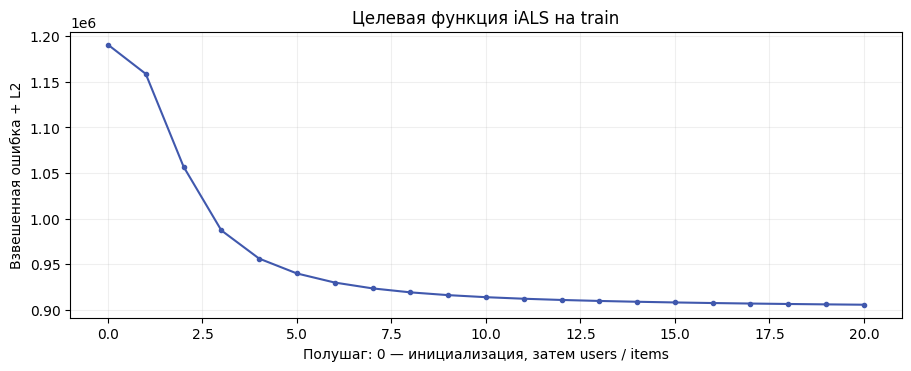

In [53]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ax.plot(np.arange(len(ials_loss_trace)), ials_loss_trace["objective"], color="#4058AD", marker="o", markersize=3)
ax.set(title="Целевая функция iALS на train", xlabel="Полушаг: 0 — инициализация, затем users / items",
       ylabel="Взвешенная ошибка + L2")
ax.grid(alpha=.2)
fig.savefig(PROJECT_ROOT / config["storage"]["results_dir"] / "figures/06_ials_training_objective.png",
            dpi=140, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)

Решатель допускает произвольный таргет $p$ на тех же положительных координатах. Это используется в пятой модели: confidence и ALS-обновления остаются прежними. Предварительная кривая objective сохранена в `results/ials_training_objective.csv`.

### 3. EASE

Для бинарной положительной истории $R$ решается

$$\min_B\|R-RB\|_F^2+\lambda\|B\|_F^2,\qquad B_{jj}=0.$$

Если $P=(R^TR+\lambda I)^{-1}$, то $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$; скор — $(R_{u,:}B)_j$. Деление идёт по **целевому** столбцу, отрицательные коэффициенты сохраняются. Обратная матрица не хранится целиком: столбцы решаются блоками после Cholesky. Общий evaluator исключает известные товары.

#### Ручная проверка

При двух товарах и $\lambda=2$ получается $B=[[0,1/4],[1/3,0]]$. Второй пример проверяет отрицательные коэффициенты и значение objective.

In [54]:
from copy import deepcopy
from models import EASE
from models.ease import ease_objective
from scipy import sparse

ease_toy_config = deepcopy(config)
ease_toy_config["split"]["validation_start_utc"] = "2020-01-02T00:00:00+00:00"
def ease_toy_history(rows):
    return pd.DataFrame([
        {"user_id": u, "item_id": i, "rating": float(r), "source_line": j + 1,
         "timestamp": pd.Timestamp("2020-01-01", tz="UTC")}
        for j, (u, i, r) in enumerate(rows)
    ])

ease_toy_two = EASE(regularization=2, solve_block_size=1).fit(
    ease_toy_history([("u0", "a", 5), ("u0", "b", 4), ("u1", "a", 5)]), ease_toy_config,
)
np.testing.assert_allclose(ease_toy_two.weights_, [[0, .25], [1/3, 0]], atol=1e-14)
ease_toy = EASE(regularization=1, solve_block_size=2).fit(
    ease_toy_history([("u0", "a", 5), ("u0", "b", 4), ("u1", "a", 4), ("u1", "c", 5)]), ease_toy_config,
)
np.testing.assert_allclose(ease_toy.weights_, [[0, .4, .4], [.5, 0, -.2], [.5, -.2, 0]], atol=1e-14)
ease_toy_r = ease_toy.interactions_.toarray()
ease_toy_direct_loss = np.square(ease_toy_r - ease_toy_r @ ease_toy.weights_).sum() + np.square(ease_toy.weights_).sum()
ease_toy_loss = ease_objective(ease_toy.interactions_, ease_toy.weights_, regularization=1, block_size=1)
np.testing.assert_allclose(ease_toy_loss["objective"], ease_toy_direct_loss)
assert ease_toy_loss["objective"] < np.square(ease_toy_r).sum()
display(pd.DataFrame(ease_toy.weights_, index=["source a", "source b", "source c"], columns=["target a", "target b", "target c"]))
pd.DataFrame([ease_toy_loss])

,target a,target b,target c
source a,0.0,0.4,0.4
source b,0.5,0.0,-0.2
source c,0.5,-0.2,0.0


,reconstruction_error,l2_penalty,objective
0,1.3,0.9,2.2


#### Проверочный запуск

На полном train используются $\lambda=100$ и блок 128. Веса EASE хранятся локально; кеш проверяет хеш данных, настроек, кода и самих весов. При `RECOMPUTE_ALL=True` обучение повторяется.

In [55]:
import json
from utils.model_checks import run_implementation_check

ease = EASE(**config["implementation_checks"]["ease"])
ease_check = run_implementation_check(ease, train_reviews, validation_stage, config, "ease")
assert not ease_check["test_used"] and not ease_check["hyperparameters_tuned"]
assert ease_check["validation"]["stage_sha256"] == validation_stage.report["stage_sha256"]
pd.DataFrame([{
    "regularization": ease.params["regularization"],
    "validation_NDCG@10": ease_check["validation"]["ndcg@10"],
    "validation_Recall@10": ease_check["validation"]["recall@10"],
    "fit_reused_cache": ease_check["fit_reused_cache"],
    "fit_current_seconds": ease_check["fit_total_seconds"],
    "original_training_compute_seconds": ease_check["fit_compute_seconds"],
    "validation_evaluation_seconds": ease_check["evaluation_seconds"],
}])

,regularization,validation_NDCG@10,validation_Recall@10,fit_reused_cache,fit_current_seconds,original_training_compute_seconds,validation_evaluation_seconds
0,100.0,0.015988,0.025204,True,1.701187,83.453713,16.543485


In [56]:
ease_details = ease.training_summary_
ease_item_count = len(validation_context.item_ids)
assert ease.weights_.shape == (ease_item_count, ease_item_count)
assert (np.diag(ease.weights_) == 0).all()
assert ease_details["negative_coefficients"] > 0
assert ease_details["negative_coefficients_kept"] and ease_details["factor_reused_gram_buffer"]
assert not ease_details["full_inverse_materialized"]
assert sum(ease_details[key] for key in ("positive_coefficients", "negative_coefficients", "zero_coefficients")) == ease_item_count ** 2
assert ease_details["training_context_sha256"] == validation_context.fingerprint
assert ease_details["memory_check_at_current_fit"]["fits_optimized_strategy"]
pd.DataFrame([{
    "history_items": ease_item_count,
    "weights_GiB": ease_details["weights_storage_bytes"] / 2**30,
    "positive_coefficients": ease_details["positive_coefficients"],
    "negative_coefficients": ease_details["negative_coefficients"],
    "zero_coefficients": ease_details["zero_coefficients"],
    "reconstruction_error": ease_details["reconstruction_error"],
    "l2_penalty": ease_details["l2_penalty"],
    "train_objective": ease_details["objective"],
}])

,history_items,weights_GiB,positive_coefficients,negative_coefficients,zero_coefficients,reconstruction_error,l2_penalty,train_objective
0,11611,1.004452,71725726,62035072,1054523,87293.500575,8317.431464,95610.932039


Предварительные метрики — в `results/ease_implementation_check.csv`; аналитические проверки и защита от нехватки памяти — в `tests/test_ease.py`.

### 4. FM с историческими признаками

`models/fm.py` реализует FM второго порядка на PyTorch. Вход: ID пользователя и товара, а также девять признаков истории — число отзывов, средняя оценка, доля положительных и индикатор пустой истории для обеих сторон; у товара ещё возраст наблюдаемой истории.

$$f(z)=w_0+\sum_jw_jz_j+\frac12\sum_{k=1}^{r}\left[\left(\sum_jv_{jk}z_j\right)^2-\sum_jv_{jk}^2z_j^2\right].$$

ID кодируются индексами без плотного one-hot. Текущая оценка используется только как метка.

#### Признаки и отрицательные примеры

Для каждой timestamp-группы признаки строятся **до** обновления истории. На наблюдаемых отзывах $y=\mathbf1[rating\ge4]$. Для каждого положительного примера берётся до $q$ разных товаров из положительного каталога, известного строго раньше, кроме уже оценённых пользователем и самого товара. Будущие положительные пары не удаляются: это создало бы утечку. Такие примеры считаются слабыми отрицательными.

Непрерывные признаки нормируются статистиками наблюдаемых train-строк; бинарные признаки сохраняются. Для validation используется снимок на $T_1$, для test после refit — новый снимок на $T_2$.

In [57]:
from copy import deepcopy
from utils.features import FEATURE_NAMES, FeatureScaler, build_fm_examples
from utils.evaluation import build_history_context

fm_toy_config = deepcopy(config)
fm_toy_config["split"]["validation_start_utc"] = "2020-01-06T00:00:00+00:00"
fm_toy_rows = [
    (0, "s", "a", 5), (0, "s", "b", 5), (0, "s", "c", 1),
    (1, "u", "a", 4), (1, "u", "d", 1), (1, "v", "b", 5),
    (2, "u", "b", 5), (2, "v", "c", 4), (2, "w", "e", 5),
    (3, "u", "e", 5), (3, "v", "d", 1),
]
fm_toy_history = pd.DataFrame([
    {"user_id": u, "item_id": i, "rating": float(r), "source_line": j + 1,
     "timestamp": pd.Timestamp("2020-01-01", tz="UTC") + pd.Timedelta(days=day)}
    for j, (day, u, i, r) in enumerate(fm_toy_rows)
])
fm_toy_context = build_history_context(fm_toy_history, fm_toy_config["split"]["validation_start_utc"], fm_toy_config)
fm_toy_examples = build_fm_examples(fm_toy_history, fm_toy_context, fm_toy_config, negatives_per_positive=2)
fm_toy_anchor = fm_toy_examples.anchor_source_lines == 4
fm_toy_negative = fm_toy_anchor & fm_toy_examples.sampled
assert [fm_toy_context.item_ids[i] for i in fm_toy_examples.items[fm_toy_negative]] == ["b"]
# Будущий положительный b допустим: в момент якоря у u ещё нет прошлых отзывов.
np.testing.assert_allclose(fm_toy_examples.raw_features[fm_toy_anchor, :4], [[0, 3, 0, 1], [0, 3, 0, 1]])
fm_toy_scaler = FeatureScaler().fit(fm_toy_examples.raw_features[~fm_toy_examples.sampled])
fm_toy_table = pd.DataFrame(fm_toy_examples.raw_features[fm_toy_anchor], columns=FEATURE_NAMES)
fm_toy_table.insert(0, "sampled_negative", fm_toy_examples.sampled[fm_toy_anchor])
fm_toy_table.insert(0, "item (synthetic)", [fm_toy_context.item_ids[i] for i in fm_toy_examples.items[fm_toy_anchor]])
display(fm_toy_table)
pd.DataFrame([{key: fm_toy_examples.report[key] for key in (
    "n_observed", "n_observed_positive", "n_observed_negative", "requested_sampled_negatives",
    "n_sampled_negatives", "anchors_with_negative_shortage", "anchors_without_prior_catalog",
)}])

,item (synthetic),sampled_negative,user.log1p_review_count,user.mean_rating,user.positive_fraction,user.empty_history,item.log1p_review_count,item.mean_rating,item.positive_fraction,item.log1p_observed_age_days,item.empty_history
0,a,False,0.0,3.0,0.0,1.0,0.693147,5.0,1.0,0.693147,0.0
1,b,True,0.0,3.0,0.0,1.0,0.693147,5.0,1.0,0.693147,0.0


,n_observed,n_observed_positive,n_observed_negative,requested_sampled_negatives,n_sampled_negatives,anchors_with_negative_shortage,anchors_without_prior_catalog
0,11,8,3,16,6,7,2


#### Проверка формулы

На синтетическом примере результат FM сравнивается с явной суммой по всем парам признаков.

In [58]:
import torch
from models.fm import FMModule

fm_formula = FMModule(2, 3, 2, 2, seed=config["seed"], init_std=.2).double()
fm_formula_users, fm_formula_items = torch.tensor([0, 1]), torch.tensor([1, 2])
fm_formula_numeric = torch.tensor([[.5, -1.], [1., .3]], dtype=torch.float64)
fm_formula_z = torch.cat((
    torch.nn.functional.one_hot(fm_formula_users, 2),
    torch.nn.functional.one_hot(fm_formula_items, 3), fm_formula_numeric,
), dim=1)
with torch.no_grad():
    fm_formula_factors = torch.cat((fm_formula.user_factors, fm_formula.item_factors, fm_formula.numeric_factors))
    fm_formula_linear = torch.cat((fm_formula.user_linear, fm_formula.item_linear, fm_formula.numeric_linear))
    fm_formula_explicit = fm_formula.bias + fm_formula_z @ fm_formula_linear
    for j in range(fm_formula_z.shape[1]):
        for k in range(j + 1, fm_formula_z.shape[1]):
            fm_formula_explicit += (fm_formula_factors[j] * fm_formula_factors[k]).sum() * fm_formula_z[:, j] * fm_formula_z[:, k]
    fm_formula_fast = fm_formula(fm_formula_users, fm_formula_items, fm_formula_numeric)
np.testing.assert_allclose(fm_formula_fast, fm_formula_explicit, atol=1e-14)
pd.DataFrame({"explicit_pair_sum": fm_formula_explicit.numpy(), "FM_formula": fm_formula_fast.numpy()})

,explicit_pair_sum,FM_formula
0,-0.086530,-0.086530
1,0.027697,0.027697


#### Обучение и ранжирование

$$L=|D|^{-1}\sum_{(z,y)\in D}\mathrm{BCEWithLogits}(f(z),y)+\frac\lambda2(\|w\|_2^2+\|V\|_F^2).$$

Используется Adam; глобальный bias не регуляризуется. Для полного каталога точный скор раскладывается на части пользователя и товара: $f(u,i)=w_0+a_u+b_i+h_u^Th_i$, где $a_u,b_i$ включают и внутригрупповые взаимодействия. Это позволяет ранжировать блоками без перебора пар признаков для каждого товара.

Проверочный запуск: `rank=32`, `lr=0,003`, `q=1`, пять эпох. Контроль только с ID обучается на тех же примерах, seed и порядке minibatch.

In [59]:
from utils.model_checks import run_fm_control_checks

fm, fm_ids_only, fm_check, fm_ids_only_check = run_fm_control_checks(train_reviews, validation_stage, config)
assert fm.examples_report_ == fm_ids_only.examples_report_
assert fm_check["validation"]["stage_sha256"] == validation_stage.report["stage_sha256"]
assert fm_ids_only_check["validation"]["stage_sha256"] == validation_stage.report["stage_sha256"]
assert not fm_check["test_used"] and not fm_check["hyperparameters_tuned"]
assert len(fm.training_summary_["numeric_features_used"]) == 9
assert fm_ids_only.training_summary_["numeric_features_used"] == []
fm_control_table = pd.read_csv(PROJECT_ROOT / "results/fm_metadata_control.csv")
display(fm_control_table.drop(columns=["examples_sha256", "stage_sha256"]))
pd.DataFrame([{
    "metadata_minus_IDs_NDCG@10": fm_check["validation"]["ndcg@10"] - fm_ids_only_check["validation"]["ndcg@10"],
    "metadata_minus_IDs_Recall@10": fm_check["validation"]["recall@10"] - fm_ids_only_check["validation"]["recall@10"],
    "fm_fit_seconds": fm_check["fit_total_seconds"],
    "IDs_only_fit_seconds": fm_ids_only_check["fit_total_seconds"],
    "fm_evaluation_seconds": fm_check["evaluation_seconds"],
}])

,model,use_metadata,ndcg@10,recall@10,epochs,n_examples
0,fm,True,0.013414,0.019796,5,224451
1,fm_ids_only,False,0.003807,0.005322,5,224451


,metadata_minus_IDs_NDCG@10,metadata_minus_IDs_Recall@10,fm_fit_seconds,IDs_only_fit_seconds,fm_evaluation_seconds
0,0.009607,0.014474,14.69646,14.242238,0.825785


In [60]:
fm_sampling_report = fm.examples_report_
display(pd.DataFrame([{name: fm_sampling_report[name] for name in (
    "n_observed", "n_observed_positive", "n_observed_negative", "requested_sampled_negatives",
    "n_sampled_negatives", "anchors_with_negative_shortage", "anchors_without_prior_catalog", "n_examples",
)}]))
assert not fm_sampling_report["future_pairs_consulted"]
assert fm_sampling_report["training_context_sha256"] == validation_context.fingerprint
np.testing.assert_array_equal(fm.scaler_.mean_, fm_ids_only.scaler_.mean_)
pd.DataFrame({"feature": FEATURE_NAMES, "train_observed_mean": fm.scaler_.mean_, "train_observed_scale": fm.scaler_.scale_})

,n_observed,n_observed_positive,n_observed_negative,requested_sampled_negatives,n_sampled_negatives,anchors_with_negative_shortage,anchors_without_prior_catalog,n_examples
0,116209,108243,7966,108243,108242,1,1,224451


,feature,train_observed_mean,train_observed_scale
0,user.log1p_review_count,0.994627,1.107143
1,user.mean_rating,3.968905,0.940165
2,user.positive_fraction,0.540763,0.479788
3,user.empty_history,0.000000,1.000000
4,item.log1p_review_count,1.919878,1.181603
5,item.mean_rating,4.481648,0.668850
6,item.positive_fraction,0.828687,0.318736
7,item.log1p_observed_age_days,5.301438,2.256574
8,item.empty_history,0.000000,1.000000


In [61]:
# Прямой forward и разложенный скоринг на небольшом блоке реального снимка.
fm_check_users = validation_stage.user_indices[:3]
fm_check_items = validation_context.catalog_items[:5]
fm_flat_users = np.repeat(fm_check_users, len(fm_check_items))
fm_flat_items = np.tile(fm_check_items, len(fm_check_users))
fm_raw_block = np.column_stack((fm.snapshot_users_raw_[fm_flat_users], fm.snapshot_items_raw_[fm_flat_items]))
with torch.no_grad():
    fm_direct_block = fm.module_(
        torch.from_numpy(fm_flat_users), torch.from_numpy(fm_flat_items),
        torch.from_numpy(fm.scaler_.transform(fm_raw_block)),
    ).numpy().reshape(len(fm_check_users), len(fm_check_items))
fm_rank_block = fm.score(fm_check_users, fm_check_items)
np.testing.assert_allclose(fm_rank_block, fm_direct_block, rtol=1e-5, atol=1e-5)
print("Максимальная ошибка float32 forward / grouped score:", float(np.max(np.abs(fm_rank_block - fm_direct_block))))

Максимальная ошибка float32 forward / grouped score: 6.253146006551802e-07


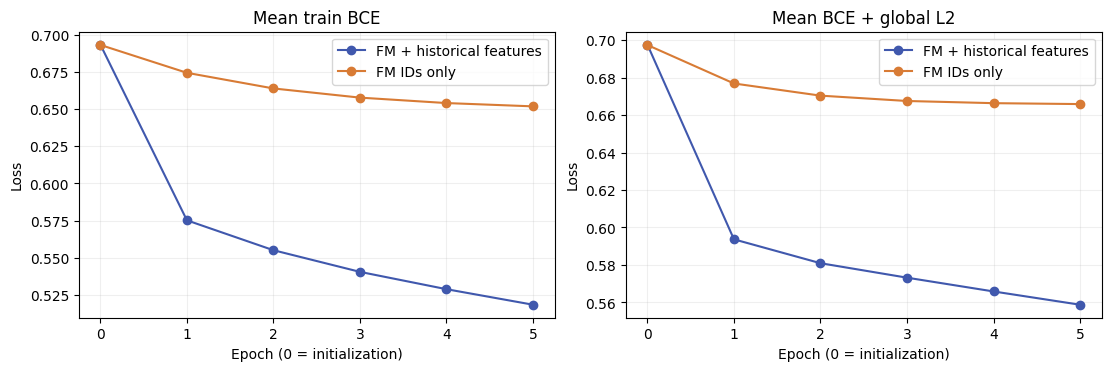

In [62]:
import matplotlib.pyplot as plt

fm_loss_trace = pd.DataFrame(fm.loss_history_)
fm_control_loss_trace = pd.DataFrame(fm_ids_only.loss_history_)
assert len(fm_loss_trace) == 1 + fm.params["epochs"]
assert fm_loss_trace["objective"].iloc[-1] < fm_loss_trace["objective"].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
for table, label, color in ((fm_loss_trace, "FM + historical features", "#4058AD"),
                            (fm_control_loss_trace, "FM IDs only", "#D87B35")):
    for ax, column in zip(axes, ("bce", "objective")):
        ax.plot(table["epoch"], table[column], marker="o", color=color, label=label)
for ax, title in zip(axes, ("Mean train BCE", "Mean BCE + global L2")):
    ax.set(xlabel="Epoch (0 = initialization)", ylabel="Loss", title=title)
    ax.grid(alpha=.2)
    ax.legend()
fig.savefig(PROJECT_ROOT / "results/figures/07_fm_training_objective.png", dpi=140, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)

Предварительные метрики FM и контроля с ID приведены выше. Финальная проверка эффекта исторических признаков — в разделе 5.

### 5. iALS с новым таргетом

Проверяется гипотеза: оценка 5 сильнее оценки 4, а свежий отзыв важнее старого. Для положительной пары и границы истории $T$:

$$s(r)=\frac{r-3}{2},\qquad a(T,t)=\frac{T-t}{86400},\qquad p_{ui}=s(r_{ui})^\gamma 2^{-a(T,t_{ui})/h}.$$

$h$ измеряется в днях; при $h=\infty$ давность отключена, при $\gamma=0$ отключена сила оценки. В пределе $\gamma=0,h=\infty$ получается бинарный iALS. Для остальных пар $p_{ui}=0$.

Решатель, регуляризация, положительные координаты и $c_{ui}=1+\alpha\mathbf1[(u,i)\in\Omega^+]$ остаются такими же, как в базовом iALS; в правой части нормальных уравнений меняется только сумма $\sum_i p_{ui}y_i$. Возраст отсчитывается от $T_1$ или $T_2$, а не от текущей даты. Релевантность на validation/test остаётся бинарной.

#### Ручная проверка

При $h=10$ дней оценка 4 десять дней назад и оценка 5 двадцать дней назад дают одинаковый таргет 0,25. Вырожденный вариант совпадает с базовым iALS побитово.

In [63]:
from copy import deepcopy
from models import CustomIALS, IALS
from models.custom_ials import custom_preferences
from models.ials import als_update
from scipy import sparse

custom_hand_times = pd.to_datetime(["2020-01-11", "2020-01-01"], utc=True)
custom_hand_p = custom_preferences([4, 5], custom_hand_times, "2020-01-21T00:00:00+00:00", gamma=1, half_life_days=10)
np.testing.assert_allclose(custom_hand_p, [.25, .25], atol=1e-15)
display(pd.DataFrame({"rating": [4, 5], "age_days": [10, 20], "custom_target": custom_hand_p}))

custom_toy_config = deepcopy(config)
custom_toy_config["split"]["validation_start_utc"] = "2020-01-21T00:00:00+00:00"
custom_toy_history = pd.DataFrame([
    {"user_id": u, "item_id": i, "rating": float(r), "timestamp": pd.Timestamp(t, tz="UTC"), "source_line": j+1}
    for j, (u, i, r, t) in enumerate([
        ("u0", "a", 4, "2020-01-01"), ("u0", "b", 1, "2020-01-05"),
        ("u1", "b", 5, "2020-01-11"), ("u1", "c", 4, "2020-01-01"),
    ])
])
custom_toy_params = dict(rank=2, regularization=.2, alpha=2.5, iterations=3, init_std=.02)
custom_toy_baseline = IALS(**custom_toy_params).fit(custom_toy_history, custom_toy_config)
custom_toy_binary_limit = CustomIALS(**custom_toy_params, gamma=0, half_life_days="infinity").fit(custom_toy_history, custom_toy_config)
np.testing.assert_array_equal(custom_toy_baseline.user_factors_, custom_toy_binary_limit.user_factors_)
np.testing.assert_array_equal(custom_toy_baseline.item_factors_, custom_toy_binary_limit.item_factors_)
assert custom_toy_baseline.loss_history_ == custom_toy_binary_limit.loss_history_
print("Бинарный предел: факторы и все значения objective совпадают побитово.")

,rating,age_days,custom_target
0,4,10,0.25
1,5,20,0.25


Бинарный предел: факторы и все значения objective совпадают побитово.


In [64]:
# p=0 на наблюдаемой координате не превращает её confidence в 1.
custom_zero_observed = sparse.csr_matrix([[1., 1.]])
custom_zero_targets = custom_zero_observed.copy()
custom_zero_targets.data[:] = [0., 1.]
custom_zero_update = als_update(custom_zero_observed, custom_zero_targets, np.array([[2.], [3.]]), alpha=2, regularization=1)
np.testing.assert_allclose(custom_zero_update, [[9/40]])
custom_toy_underflow = CustomIALS(rank=2, iterations=2, half_life_days=1e-300).fit(custom_toy_history, custom_toy_config)
assert custom_toy_underflow.targets_.nnz == custom_toy_underflow.observed_.nnz == 3
np.testing.assert_array_equal(custom_toy_underflow.targets_.data, np.zeros(3))
print("Нулевой target сохраняет координату; обновление x=9/40 и underflow проверены.")

Нулевой target сохраняет координату; обновление x=9/40 и underflow проверены.


#### Четыре проверочных сигнала

При общих `rank=32`, $\lambda=0{,}1$, $\alpha=10$, 10 итерациях и seed=42 сравниваются бинарный таргет, только оценка, только давность ($h=730$) и их сочетание. Это проверка реализации; для итогового сравнения параметры выбираются ниже.

In [65]:
from utils.model_checks import run_custom_ials_control_checks

custom_models, custom_reports = run_custom_ials_control_checks(train_reviews, validation_stage, config)
custom_ials = custom_models["rating_and_recency"]
custom_binary = custom_models["binary"]
np.testing.assert_array_equal(custom_binary.user_factors_, ials.user_factors_)
np.testing.assert_array_equal(custom_binary.item_factors_, ials.item_factors_)
for variant, model in custom_models.items():
    report = custom_reports[variant]
    assert not report["test_used"] and not report["hyperparameters_tuned"]
    assert report["validation"]["stage_sha256"] == validation_stage.report["stage_sha256"]
    assert report["validation"]["n_users"] == 2726 and report["validation"]["n_relevant_pairs"] == 8005
    assert model.training_summary_["observed_pattern_sha256"] == custom_binary.training_summary_["observed_pattern_sha256"]
    for name in ("rank", "regularization", "alpha", "iterations", "init_std"):
        assert model.params[name] == custom_binary.params[name]
assert not custom_ials.training_summary_["recovers_binary_target"]
assert custom_ials.training_summary_["target_reference_cutoff_utc"] == validation_context.cutoff.isoformat()
custom_target_comparison = pd.read_csv(PROJECT_ROOT / "results/custom_ials_target_control.csv")
custom_target_comparison[["variant", "gamma", "half_life_days", "ndcg@10", "recall@10", "ndcg_delta_vs_binary", "recall_delta_vs_binary"]]

,variant,gamma,half_life_days,ndcg@10,recall@10,ndcg_delta_vs_binary,recall_delta_vs_binary
0,binary,0.0,inf,0.015885,0.022848,0.000000,0.000000
1,rating_only,1.0,inf,0.015465,0.023103,-0.000419,0.000254
2,recency_only,0.0,730.0,0.019067,0.028636,0.003182,0.005788
3,rating_and_recency,1.0,730.0,0.018197,0.026520,0.002312,0.003672


In [66]:
custom_target_distribution = pd.read_csv(PROJECT_ROOT / "results/custom_ials_target_distribution.csv")
assert custom_target_distribution["n_values"].eq(validation_context.positive.nnz).all()
display(custom_target_distribution)
# Примеры по реальным группам train: только агрегаты, без ID/индивидуальных строк.
custom_target_groups = pd.read_csv(PROJECT_ROOT / "results/custom_ials_target_by_rating_age.csv")
assert custom_target_groups["n_positive_reviews"].sum() == validation_context.positive.nnz
custom_target_groups.assign(binary_target_mean=1.)

,variant,n_values,zero_targets,min,q01,q25,median,q75,q99,max,mean
0,binary,108243,0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,rating_only,108243,0,0.500000,0.500000,1.000000,1.000000,1.000000,1.000000,1.000000,0.924087
2,recency_only,108243,0,0.001987,0.056516,0.392106,0.569462,0.730307,0.986795,0.999051,0.569490
3,rating_and_recency,108243,0,0.001656,0.039413,0.338765,0.528308,0.701756,0.984530,0.999051,0.529191


,rating,age_band_days,n_positive_reviews,median_age_days,rating_only_mean,recency_only_mean,custom_target_mean,custom_target_min,custom_target_max,binary_target_mean
0,4.0,"(0,180]",1874,90.0,0.5,0.922287,0.461144,0.421447,0.499525,1.0
1,4.0,"(180,730]",7117,471.0,0.5,0.647576,0.323788,0.250000,0.421047,1.0
2,4.0,"(730,infinity)",7443,1155.0,0.5,0.320718,0.160359,0.001656,0.249763,1.0
3,5.0,"(0,180]",12289,94.0,1.0,0.920010,0.920010,0.842895,0.999051,1.0
4,5.0,"(180,730]",46303,468.0,1.0,0.650583,0.650583,0.500000,0.842095,1.0
5,5.0,"(730,infinity)",33217,1109.0,1.0,0.345880,0.345880,0.001987,0.499525,1.0


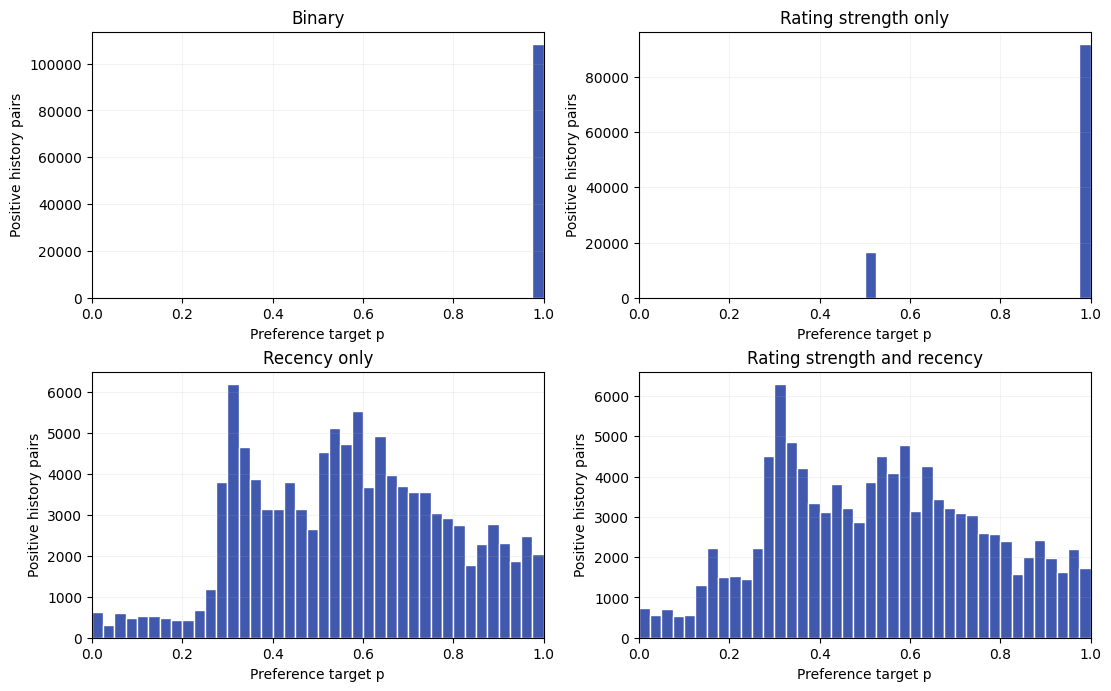

In [67]:
import matplotlib.pyplot as plt

custom_variant_names = {
    "binary": "Binary", "rating_only": "Rating strength only",
    "recency_only": "Recency only", "rating_and_recency": "Rating strength and recency",
}
fig, axes = plt.subplots(2, 2, figsize=(11, 6.8), layout="constrained")
for ax, (variant, model) in zip(axes.ravel(), custom_models.items()):
    ax.hist(model.targets_.data, bins=np.linspace(0, 1, 41), color="#4058AD", edgecolor="white")
    ax.set(title=custom_variant_names[variant], xlabel="Preference target p", ylabel="Positive history pairs", xlim=(0, 1))
    ax.grid(alpha=.15)
fig.savefig(PROJECT_ROOT / "results/figures/08_custom_target_distribution.png", dpi=140, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)

#### Проверка обучения

Для каждого таргета показано снижение собственной train objective. Абсолютные значения loss разных таргетов не сравнивают их качество; для этого используются общие метрики.

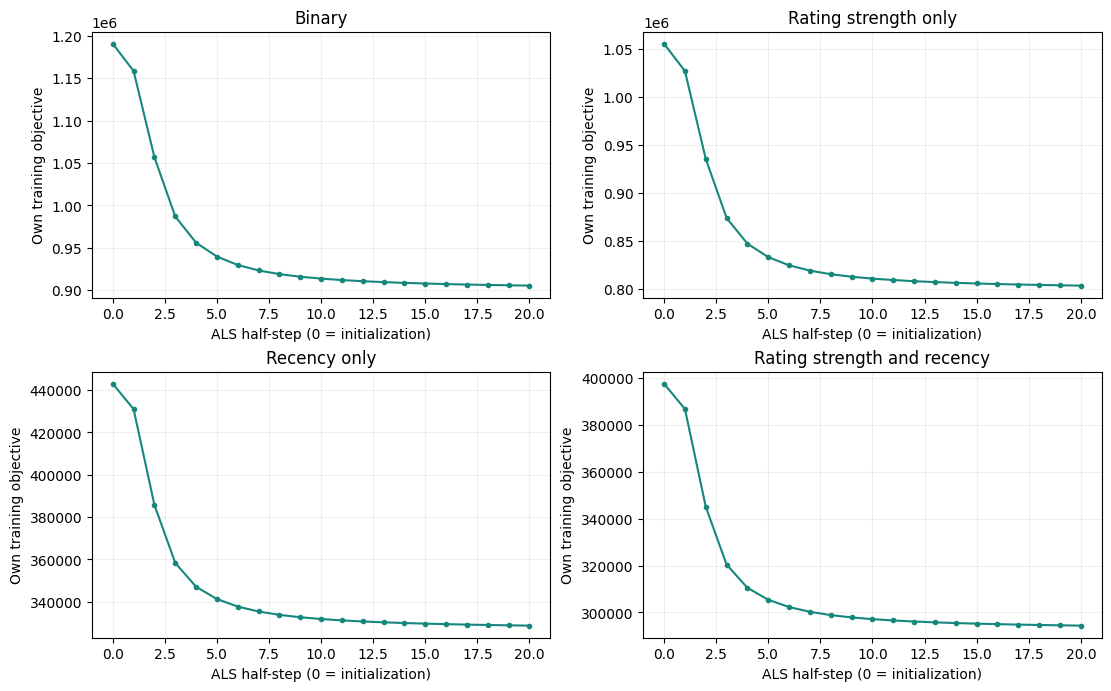

In [68]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.8), layout="constrained")
for ax, (variant, model) in zip(axes.ravel(), custom_models.items()):
    trace = pd.DataFrame(model.loss_history_)
    values = trace["objective"].to_numpy()
    assert len(values) == 1 + 2 * model.params["iterations"]
    assert (np.diff(values) <= 1e-8 * np.maximum(1, np.abs(values[:-1]))).all()
    ax.plot(np.arange(len(values)), values, marker="o", markersize=3, color="#16877C")
    ax.set(title=custom_variant_names[variant], xlabel="ALS half-step (0 = initialization)", ylabel="Own training objective")
    ax.grid(alpha=.2)
fig.savefig(PROJECT_ROOT / "results/figures/09_custom_ials_training_objective.png", dpi=140, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)

Проверочные метрики и распределения таргетов сохранены в `results/custom_ials_target_control.csv` и соседних агрегированных таблицах. Веса и индивидуальные строки остаются локально.

### Подбор по validation

Бюджет: 12 вариантов kNN, 12 iALS, 4 EASE, 12 FM и 6 кастомных iALS; seed=42. Выбор — максимальная NDCG@10, затем меньший rank/число соседей и лексикографический порядок настроек. Recall на выбор не влияет.

Для FM проверяются эпохи до 20 с `patience=3`; сохраняется лучшая эпоха, при равенстве — более ранняя. Сначала выбирается базовый iALS, затем с его структурными параметрами сравниваются $\gamma\in\{0{,}5;1\}$ и $h\in\{180;730;\infty\}$. Дополнительные контроли: FM только с ID и iALS только с давностью. Конфигурации и правила зафиксированы до test.

In [69]:
from utils.search import generate_search_manifest

search_manifest_preview = generate_search_manifest(config)
search_counts = pd.Series([r["model"] for r in search_manifest_preview["trials"]]).value_counts(sort=False)
assert search_counts.sum() == 46
assert search_manifest_preview["controls"]["additional_training_trials"] == 2
display(search_counts.rename("candidate_count").rename_axis("model").reset_index())
search_random_candidates = pd.DataFrame([
    {"trial_id": r["trial_id"], "params": json.dumps(r["params_template"], sort_keys=True)}
    for r in search_manifest_preview["trials"] if r["model"] in ("ials", "fm")
])
with pd.option_context("display.max_rows", 24, "display.max_colwidth", 180):
    display(search_random_candidates)

,model,candidate_count
0,item_knn,12
1,ials,12
2,ease,4
3,fm,12
4,custom_ials,6


,trial_id,params
0,ials_01,"{""alpha"": 10, ""init_std"": 0.01, ""iterations"": 10, ""rank"": 64, ""regularization"": 0.01}"
1,ials_02,"{""alpha"": 1, ""init_std"": 0.01, ""iterations"": 10, ""rank"": 32, ""regularization"": 0.1}"
2,ials_03,"{""alpha"": 10, ""init_std"": 0.01, ""iterations"": 20, ""rank"": 32, ""regularization"": 1.0}"
3,ials_04,"{""alpha"": 10, ""init_std"": 0.01, ""iterations"": 20, ""rank"": 128, ""regularization"": 0.01}"
4,ials_05,"{""alpha"": 10, ""init_std"": 0.01, ""iterations"": 20, ""rank"": 64, ""regularization"": 0.01}"
5,ials_06,"{""alpha"": 40, ""init_std"": 0.01, ""iterations"": 10, ""rank"": 64, ""regularization"": 0.1}"
6,ials_07,"{""alpha"": 1, ""init_std"": 0.01, ""iterations"": 10, ""rank"": 128, ""regularization"": 0.1}"
7,ials_08,"{""alpha"": 40, ""init_std"": 0.01, ""iterations"": 20, ""rank"": 32, ""regularization"": 0.01}"
8,ials_09,"{""alpha"": 40, ""init_std"": 0.01, ""iterations"": 20, ""rank"": 128, ""regularization"": 1.0}"
9,ials_10,"{""alpha"": 40, ""init_std"": 0.01, ""iterations"": 20, ""rank"": 32, ""regularization"": 0.1}"


#### Полный поиск

`python -m utils.search` запускает поиск; `--no-cache` пересчитывает попытки. В ноутбуке для этого служит `RECOMPUTE_ALL=True`. Кеш сверяет код, данные, разбиение, признаки, настройки и seed. В таблицах время обучения отделено от чтения кеша.

In [70]:
import gc
from utils.search import run_validation_search

del ease, item_knn, ials, fm, fm_ids_only, custom_models, custom_ials, custom_binary
gc.collect()
validation_search = run_validation_search(
    train_reviews, validation_stage, config,
    reuse=config["runtime"].get("reuse_model_cache", True),
)
assert validation_search["summary"]["status"] == "complete"
assert validation_search["summary"]["completed_primary_trials"] == 46
assert validation_search["summary"]["completed_control_trials"] == 2
assert not validation_search["test_used"]
search_trials = validation_search["trials"]
assert search_trials["status"].eq("ok").all()
assert search_trials["stage_sha256"].eq(validation_stage.report["stage_sha256"]).all()
assert search_trials["n_users"].eq(len(validation_stage.user_indices)).all()
pd.DataFrame([{**validation_search["summary"],
    "sum_original_trial_fit_and_eval_seconds": float(search_trials["fit_seconds"].sum() + search_trials["evaluation_seconds"].sum()),
}])

,search_key,status,expected_primary_trials,completed_primary_trials,completed_control_trials,result_cache_hits,current_invocation_seconds,test_used,sum_original_trial_fit_and_eval_seconds
0,0ae57715c370d9a5446f3130a1b25c2e14f386098e9f83...,complete,46,46,2,48,0.160821,False,2127.335901


In [71]:
search_preflight = json.loads((PROJECT_ROOT / "results/search_preflight.json").read_text())
assert search_preflight["ease_memory"]["fits_optimized_strategy"]
assert not search_preflight["budget_reduced"] and not search_preflight["test_used"]
assert all(not row["validation_labels_used"] for row in search_preflight["train_only_probes"])
display(pd.DataFrame(search_preflight["train_only_probes"]))
search_selected = validation_search["best_params"]
search_best_table = pd.DataFrame([
    {"model": name, "trial_id": entry["trial_id"],
     "validation_NDCG@10": entry["validation"]["ndcg@10"],
     "validation_Recall@10": entry["validation"]["recall@10"],
     "selected_params": json.dumps(entry["params"], sort_keys=True)}
    for name, entry in search_selected.items()
])
assert set(search_selected) == {"item_knn", "ials", "ease", "fm", "custom_ials"}
for key in ("rank", "regularization", "alpha", "iterations", "init_std"):
    assert search_selected["ials"]["params"][key] == search_selected["custom_ials"]["params"][key]
with pd.option_context("display.max_colwidth", 180):
    display(search_best_table)

,kernel,params,fit_and_score_seconds,n_history_rows,validation_labels_used
0,ials_max_rank,"{'rank': 128, 'regularization': 0.1, 'alpha': ...",0.495639,4795,False
1,fm_max_rank_q,"{'rank': 64, 'negatives_per_positive': 4, 'bat...",1.499071,4795,False


,model,trial_id,validation_NDCG@10,validation_Recall@10,selected_params
0,item_knn,item_knn_08,0.016465,0.025365,"{""k_neighbors"": 200, ""shrinkage"": 10.0, ""similarity_block_size"": 256}"
1,ials,ials_04,0.020017,0.029228,"{""alpha"": 10.0, ""init_std"": 0.01, ""iterations"": 20, ""rank"": 128, ""regularization"": 0.01}"
2,ease,ease_03,0.015988,0.025204,"{""regularization"": 100.0, ""solve_block_size"": 128}"
3,fm,fm_09,0.018427,0.030691,"{""batch_size"": 1024, ""epochs"": 8, ""init_std"": 0.01, ""l2"": 0.0001, ""learning_rate"": 0.001, ""negatives_per_positive"": 4, ""rank"": 16, ""use_metadata"": true}"
4,custom_ials,custom_ials_05,0.022397,0.034148,"{""alpha"": 10.0, ""gamma"": 1.0, ""half_life_days"": 180.0, ""init_std"": 0.01, ""iterations"": 20, ""rank"": 128, ""regularization"": 0.01}"


In [72]:
# Компактный журнал; полный список параметров и статусов — в validation_trials.csv.
search_journal_columns = ["trial_id", "model", "purpose", "status", "validation_ndcg_at_10",
                          "validation_recall_at_10", "selected_epoch", "epochs_completed",
                          "fit_seconds", "result_cache_hit"]
with pd.option_context("display.max_rows", 50):
    display(search_trials[search_journal_columns])

,trial_id,model,purpose,status,validation_ndcg_at_10,validation_recall_at_10,selected_epoch,epochs_completed,fit_seconds,result_cache_hit
0,item_knn_01,item_knn,search,ok,0.012231,0.020235,NaN,NaN,1.556764,True
1,item_knn_02,item_knn,search,ok,0.016456,0.025367,NaN,NaN,1.575314,True
2,item_knn_03,item_knn,search,ok,0.016058,0.024123,NaN,NaN,1.600579,True
3,item_knn_04,item_knn,search,ok,0.011530,0.016748,NaN,NaN,1.527462,True
4,item_knn_05,item_knn,search,ok,0.016120,0.024871,NaN,NaN,1.619465,True
5,item_knn_06,item_knn,search,ok,0.015749,0.023975,NaN,NaN,1.487071,True
6,item_knn_07,item_knn,search,ok,0.011480,0.017938,NaN,NaN,1.548770,True
7,item_knn_08,item_knn,search,ok,0.016465,0.025365,NaN,NaN,1.636865,True
8,item_knn_09,item_knn,search,ok,0.015992,0.023935,NaN,NaN,1.543770,True
9,item_knn_10,item_knn,search,ok,0.012007,0.018673,NaN,NaN,1.443081,True


#### Результаты поиска

График показывает все просмотренные параметры; выделены выбранные конфигурации. Полные строки доступны в `results/validation_trials.csv`.

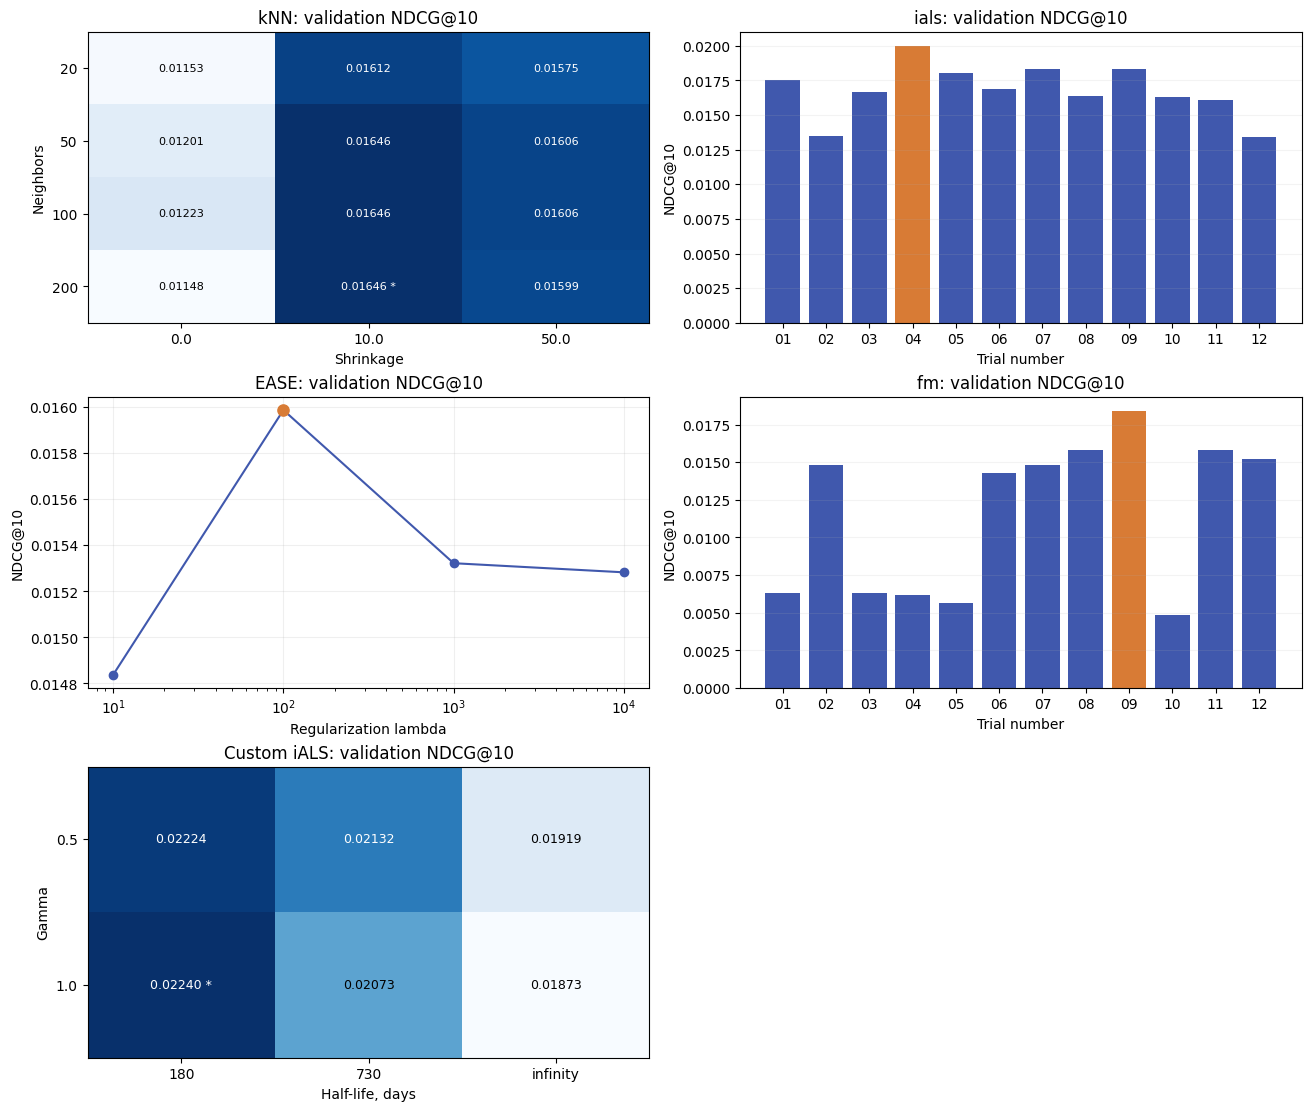

In [73]:
import matplotlib.pyplot as plt

search_primary = search_trials.loc[search_trials.purpose.eq("search")].copy()
search_primary["parameters"] = search_primary.selected_params.map(json.loads)
fig, axes = plt.subplots(3, 2, figsize=(13, 11), layout="constrained")
knn_trials = search_primary.loc[search_primary.model.eq("item_knn")]
knn_grid = pd.DataFrame([{"k": r.parameters["k_neighbors"], "shrinkage": r.parameters["shrinkage"],
                          "score": r.validation_ndcg_at_10} for r in knn_trials.itertuples()]).pivot(index="k", columns="shrinkage", values="score")
ax = axes[0, 0]
ax.imshow(knn_grid, cmap="Blues", aspect="auto")
ax.set(xticks=range(len(knn_grid.columns)), xticklabels=knn_grid.columns,
       yticks=range(len(knn_grid.index)), yticklabels=knn_grid.index,
       title="kNN: validation NDCG@10", xlabel="Shrinkage", ylabel="Neighbors")
knn_best = search_selected["item_knn"]["params"]
for row, k in enumerate(knn_grid.index):
    for col, shrink in enumerate(knn_grid.columns):
        mark = " *" if k == knn_best["k_neighbors"] and shrink == knn_best["shrinkage"] else ""
        ax.text(col, row, f"{knn_grid.iloc[row, col]:.5f}{mark}", ha="center", va="center", fontsize=8,
                color="white" if knn_grid.iloc[row, col] > knn_grid.to_numpy().mean() else "black")
for model_name, ax in (("ials", axes[0, 1]), ("fm", axes[1, 1])):
    rows = search_primary.loc[search_primary.model.eq(model_name)]
    colors = ["#D87B35" if t == search_selected[model_name]["trial_id"] else "#4058AD" for t in rows.trial_id]
    ax.bar(np.arange(len(rows)), rows.validation_ndcg_at_10, color=colors)
    ax.set(xticks=np.arange(len(rows)), xticklabels=[t.rsplit("_", 1)[-1] for t in rows.trial_id],
           title=f"{model_name}: validation NDCG@10", xlabel="Trial number", ylabel="NDCG@10")
    ax.grid(axis="y", alpha=.15)
ease_trials = search_primary.loc[search_primary.model.eq("ease")].sort_values("trial_id")
ease_lambdas = np.array([p["regularization"] for p in ease_trials.parameters])
ax = axes[1, 0]
order = np.argsort(ease_lambdas)
ax.semilogx(ease_lambdas[order], ease_trials.validation_ndcg_at_10.to_numpy()[order], marker="o", color="#4058AD")
ease_best = search_selected["ease"]
ax.scatter([ease_best["params"]["regularization"]], [ease_best["validation"]["ndcg@10"]], color="#D87B35", s=65, zorder=3)
ax.set(title="EASE: validation NDCG@10", xlabel="Regularization lambda", ylabel="NDCG@10")
ax.grid(alpha=.2)
custom_trials = search_primary.loc[search_primary.model.eq("custom_ials")]
custom_grid = pd.DataFrame([{"gamma": r.parameters["gamma"],
                             "h": "infinity" if r.parameters["half_life_days"] == "infinity" else f"{r.parameters['half_life_days']:g}",
                             "score": r.validation_ndcg_at_10} for r in custom_trials.itertuples()]).pivot(index="gamma", columns="h", values="score")
custom_grid = custom_grid[["180", "730", "infinity"]]
ax = axes[2, 0]
ax.imshow(custom_grid, cmap="Blues", aspect="auto")
ax.set(xticks=range(len(custom_grid.columns)), xticklabels=custom_grid.columns,
       yticks=range(len(custom_grid.index)), yticklabels=custom_grid.index,
       title="Custom iALS: validation NDCG@10", xlabel="Half-life, days", ylabel="Gamma")
custom_best = search_selected["custom_ials"]["params"]
best_h = "infinity" if custom_best["half_life_days"] == "infinity" else f"{custom_best['half_life_days']:g}"
for row, gamma in enumerate(custom_grid.index):
    for col, h in enumerate(custom_grid.columns):
        mark = " *" if gamma == custom_best["gamma"] and h == best_h else ""
        ax.text(col, row, f"{custom_grid.iloc[row, col]:.5f}{mark}", ha="center", va="center", fontsize=9,
                color="white" if custom_grid.iloc[row, col] > custom_grid.to_numpy().mean() else "black")
axes[2, 1].set_visible(False)
fig.savefig(PROJECT_ROOT / "results/figures/10_validation_search.png", dpi=140, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)

#### Эпохи FM

Синяя кривая — выбранная конфигурация. Отмечена лучшая восстановленная эпоха, а не последний шаг обучения.

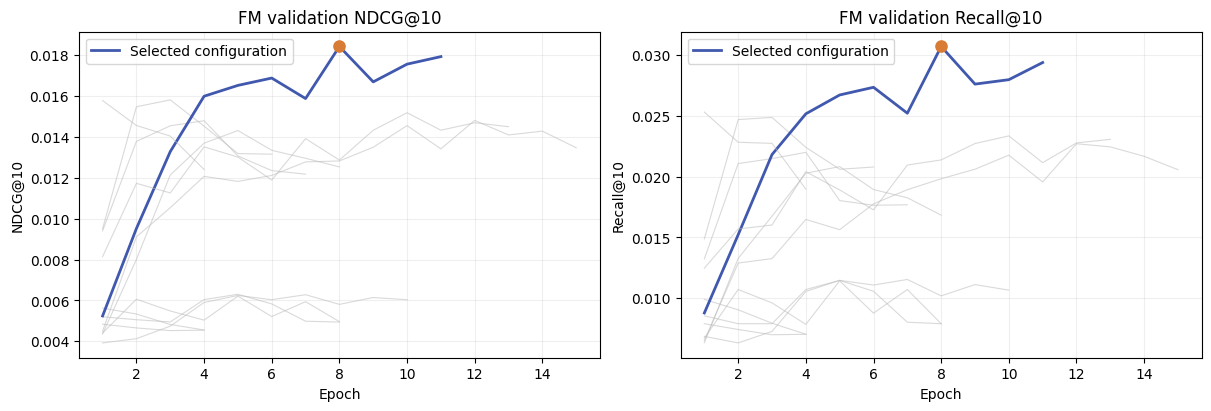

,epochs_visited,selected_epoch,best_ndcg
trial_id,,,
fm_01,10,7,0.006282
fm_02,7,4,0.014795
fm_03,8,5,0.006302
fm_04,8,5,0.006212
fm_05,4,1,0.005626
fm_06,8,5,0.014316
fm_07,15,12,0.014810
fm_08,6,3,0.015813
fm_09,11,8,0.018427


In [74]:
fm_search_epochs = validation_search["fm_epochs"]
fm_selected_trial = search_selected["fm"]["trial_id"]
fm_selected_epoch = search_selected["fm"]["params"]["epochs"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for trial_id, trace in fm_search_epochs.groupby("trial_id", sort=False):
    chosen = trial_id == fm_selected_trial
    for ax, metric in zip(axes, ("ndcg@10", "recall@10")):
        ax.plot(trace.epoch, trace[metric], color="#4058AD" if chosen else "#BBBBBB",
                linewidth=2 if chosen else .8, alpha=1 if chosen else .55,
                label="Selected configuration" if chosen else None)
        if chosen:
            selected_row = trace.loc[trace.epoch.eq(fm_selected_epoch)].iloc[0]
            ax.scatter([fm_selected_epoch], [selected_row[metric]], color="#D87B35", s=65, zorder=5)
for ax, metric in zip(axes, ("NDCG@10", "Recall@10")):
    ax.set(xlabel="Epoch", ylabel=metric, title=f"FM validation {metric}")
    ax.grid(alpha=.2)
    ax.legend()
fig.savefig(PROJECT_ROOT / "results/figures/11_fm_validation_epochs.png", dpi=140, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)
fm_visited = fm_search_epochs.groupby("trial_id").agg(epochs_visited=("epoch", "max"), selected_epoch=("selected_epoch", "first"), best_ndcg=("ndcg@10", "max"))
display(fm_visited)
assert fm_visited.loc[fm_selected_trial, "selected_epoch"] == fm_selected_epoch

In [75]:
# Контроли с выбранными настройками; одинаковый stage и структурные параметры.
validation_controls = validation_search["controls"]
assert validation_controls["stage_sha256"].eq(validation_stage.report["stage_sha256"]).all()
display(validation_controls.drop(columns=["params", "stage_sha256"]))
final_experiment_plan = validation_search["final_plan"]
assert final_experiment_plan["settings_fixed_before_test"] and not final_experiment_plan["test_used"]
assert final_experiment_plan["refit_cutoff_utc"] == config["split"]["test_start_utc"]
assert len(final_experiment_plan["models"]) == 8
pd.DataFrame([{"experiment": name, "model": entry["model"], "role": entry["role"], "validation_trial_id": entry["validation_trial_id"]}
              for name, entry in final_experiment_plan["models"].items()])

,family,variant,trial_id,ndcg@10,recall@10,ndcg_delta_vs_reference,recall_delta_vs_reference
0,custom_target,binary,ials_04,0.020017,0.029228,0.000000,0.000000
1,custom_target,rating_only,custom_ials_04,0.018725,0.028146,-0.001292,-0.001082
2,custom_target,recency_only,control_custom_recency_only,0.023154,0.036071,0.003137,0.006843
3,custom_target,rating_and_recency,custom_ials_05,0.022397,0.034148,0.002380,0.004920
4,fm_metadata,with_metadata,fm_09,0.018427,0.030691,0.015036,0.025794
5,fm_metadata,IDs_only,control_fm_ids_only,0.003391,0.004897,0.000000,0.000000


,experiment,model,role,validation_trial_id
0,item_knn,item_knn,primary,item_knn_08
1,ials,ials,primary,ials_04
2,ease,ease,primary,ease_03
3,fm,fm,primary,fm_09
4,custom_ials,custom_ials,primary,custom_ials_05
5,fm_ids_only,fm,control,control_fm_ids_only
6,custom_ials_rating_only,custom_ials,control,custom_ials_04
7,custom_ials_recency_only,custom_ials,control,control_custom_recency_only


Выбранные настройки записаны в `results/best_params.json`. Сначала фиксируются они и набор контрольных сравнений, затем выполняется refit и оценка на test. Лучшие validation-метрики могут быть оптимистичны из-за подбора.

<a id="comparison"></a>

## 5. Итоговое сравнение при K=10

Выбранные по validation настройки зафиксированы до test. Каждая модель переобучается на train+validation до $T_2$; ID-словари и признаки FM строятся заново, возраст для нового таргета пересчитывается. Общий test-набор, маска известных товаров и правило равных скоров одинаковы для всех восьми запусков.

Обучение идёт последовательно, по одному CPU-потоку в отдельном процессе. В таблице разделены время fit, время выдачи top-10 и пик памяти всего процесса (Linux VmHWM). При чтении проверенного кеша сохраняются измерения исходного полного запуска.

In [76]:
from final_evaluation import run_final_evaluation

final_run = run_final_evaluation(
    periods, config, reuse=config["runtime"].get("reuse_model_cache", True),
)
assert final_run["summary"]["status"] == "complete"
assert final_run["summary"]["completed_experiments"] == 8
assert final_run["test_used"]
final_metrics = final_run["metrics"]
assert final_metrics["status"].eq("ok").all()
assert final_metrics["stage_sha256"].nunique() == 1
assert final_metrics["n_users"].nunique() == 1
assert final_metrics["n_relevant_pairs"].nunique() == 1
assert final_metrics["n_items"].nunique() == 1
pd.DataFrame([final_run["summary"]])

,status,expected_experiments,completed_experiments,result_cache_hits,comparison_sha256,final_cache_key,runner_code_sha256,test_stage_sha256,current_invocation_seconds,test_used
0,complete,8,8,8,80f1095b165f9b39f3df92e94f57022fd11cdbbaf8fd59...,f173192f49b4adca4232ff9c796992030436f0f0276a3c...,31d0ee23913b9e719536f2c88a38ca4d3377f713c58ef4...,2cc1c5091950a1ddba6c627c78378884753f5a4beb45dc...,6.056544,True


In [77]:
test_report = final_run["test_stage_report"]
assert test_report["cutoff_utc"] == config["split"]["test_start_utc"]
assert test_report["test_labels_used"]
assert test_report["history_context_sha256"] != validation_context.fingerprint
display(pd.DataFrame([{key: test_report[key] for key in (
    "history_n_users", "history_n_items", "history_seen_pairs", "history_positive_pairs",
    "n_catalog_items", "n_evaluation_users", "n_relevant_pairs",
    "mean_candidates_per_evaluation_user", "min_candidates_per_evaluation_user",
)}]))
display(pd.DataFrame([test_report["cold_start"]]))
display(pd.DataFrame(test_report["positive_event_audit"]))
pd.DataFrame(test_report["user_audit"])

,history_n_users,history_n_items,history_seen_pairs,history_positive_pairs,n_catalog_items,n_evaluation_users,n_relevant_pairs,mean_candidates_per_evaluation_user,min_candidates_per_evaluation_user
0,15972,11774,130787,122129,11758,2614,8438,11748.909717,11213


,cold_user_ids,fraction_held_out_user_ids,new_user_ids,known_users_without_positive_history,out_of_catalog_item_ids,fraction_held_out_item_ids,new_item_ids,known_items_without_positive_history,positive_events_with_cold_user,positive_events_with_out_of_catalog_item,positive_events_with_either,fraction_positive_events_with_either
0,612,0.182905,594,18,32,0.004767,23,9,5201,173,5322,0.386773


,rule,input_positive_events,removed_positive_events,remaining_positive_events
0,warm_user,13760,5201,8559
1,item_in_catalog,8559,121,8438
2,exclude_all_seen,8438,0,8438
3,enough_candidates,8438,0,8438


,rule,remaining_users
0,held_out_users,3346
1,warm_user,2734
2,enough_candidates,2734
3,has_relevant_candidate,2614


### Основные методы и контроли

Первые пять строк — основные модели, ещё три — варианты для проверки влияния признаков FM и частей нового таргета. Полные настройки и точные значения сохранены в `results/final_metrics.csv`.

In [78]:
def concise_final_params(row):
    p = json.loads(row["selected_hyperparameters"])
    family = row["model_family"]
    if family == "item_knn":
        return f"k={p['k_neighbors']}; shrinkage={p['shrinkage']:g}"
    if family == "ease":
        return f"lambda={p['regularization']:g}"
    if family == "fm":
        return (f"rank={p['rank']}; lr={p['learning_rate']:g}; L2={p['l2']:g}; "
                f"q={p['negatives_per_positive']}; epochs={p['epochs']}; metadata={p['use_metadata']}")
    text = f"rank={p['rank']}; lambda={p['regularization']:g}; alpha={p['alpha']:g}; iter={p['iterations']}"
    if family == "custom_ials":
        text += f"; gamma={p['gamma']:g}; h={p['half_life_days']}"
    return text

final_display = final_metrics.assign(hyperparameters=final_metrics.apply(concise_final_params, axis=1))
with pd.option_context("display.max_colwidth", None):
    display(final_display[["model", "role", "validation_ndcg_at_10", "test_ndcg_at_10", "test_recall_at_10",
                           "hyperparameters", "seed", "fit_seconds", "inference_seconds"]].round(5))

,model,role,validation_ndcg_at_10,test_ndcg_at_10,test_recall_at_10,hyperparameters,seed,fit_seconds,inference_seconds
0,item_knn,primary,0.01646,0.01768,0.02696,k=200; shrinkage=10,42,1.33251,1.15734
1,ials,primary,0.02002,0.01901,0.02809,rank=128; lambda=0.01; alpha=10; iter=20,42,110.68225,1.09913
2,ease,primary,0.01599,0.01992,0.02902,lambda=100,42,98.71815,18.86080
3,fm,primary,0.01843,0.01269,0.01755,rank=16; lr=0.001; L2=0.0001; q=4; epochs=8; metadata=True,42,38.39043,0.94593
4,custom_ials,primary,0.02240,0.01887,0.02868,rank=128; lambda=0.01; alpha=10; iter=20; gamma=1; h=180.0,42,116.44067,1.04702
5,fm_ids_only,control,0.00339,0.00514,0.00707,rank=16; lr=0.001; L2=0.0001; q=4; epochs=8; metadata=False,42,37.37359,0.86188
6,custom_ials_rating_only,control,0.01873,0.01875,0.02729,rank=128; lambda=0.01; alpha=10; iter=20; gamma=1; h=infinity,42,118.85033,1.04529
7,custom_ials_recency_only,control,0.02315,0.02029,0.03093,rank=128; lambda=0.01; alpha=10; iter=20; gamma=0; h=180.0,42,117.87932,0.89633


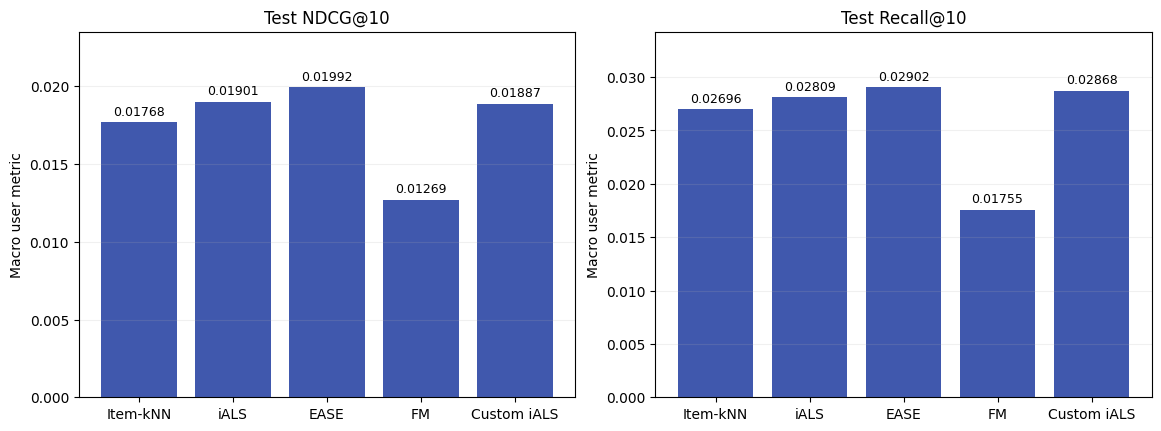

In [79]:
import matplotlib.pyplot as plt

final_primary = final_metrics.loc[final_metrics.role.eq("primary")]
assert final_primary.model.tolist() == ["item_knn", "ials", "ease", "fm", "custom_ials"]
final_primary_labels = ["Item-kNN", "iALS", "EASE", "FM", "Custom iALS"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout="constrained")
for ax, column, title in zip(axes, ("test_ndcg_at_10", "test_recall_at_10"), ("Test NDCG@10", "Test Recall@10")):
    bars = ax.bar(np.arange(len(final_primary)), final_primary[column], color="#4058AD")
    ax.set(xticks=np.arange(len(final_primary)), xticklabels=final_primary_labels, title=title, ylabel="Macro user metric")
    ax.bar_label(bars, fmt="%.5f", padding=3, fontsize=9)
    ax.set_ylim(0, final_primary[column].max() * 1.18)
    ax.grid(axis="y", alpha=.18)
fig.savefig(PROJECT_ROOT / "results/figures/12_final_test_metrics.png", dpi=140, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)

### Время и память

Peak RSS включает библиотеки, данные, обучение и выдачу; размер весов показан отдельно. Время fit не включает запуск рабочего процесса.

In [80]:
final_resources = final_metrics.assign(
    baseline_RSS_GiB=final_metrics.baseline_worker_rss_bytes / 2**30,
    peak_RSS_GiB=final_metrics.peak_worker_rss_bytes / 2**30,
    parameters_MiB=final_metrics.parameter_storage_bytes / 2**20,
)
assert (final_resources.peak_worker_rss_bytes >= final_resources.baseline_worker_rss_bytes).all()
assert not final_metrics.model_fit_reused_cache.any()
final_resources[["model", "role", "fit_seconds", "inference_seconds", "metrics_seconds",
                 "baseline_RSS_GiB", "peak_RSS_GiB", "parameters_MiB", "result_cache_hit"]].round(3)

,model,role,fit_seconds,inference_seconds,metrics_seconds,baseline_RSS_GiB,peak_RSS_GiB,parameters_MiB,result_cache_hit
0,item_knn,primary,1.333,1.157,0.003,0.312,0.361,14.674,True
1,ials,primary,110.682,1.099,0.003,0.312,0.373,27.096,True
2,ease,primary,98.718,18.861,0.003,0.310,2.386,1057.641,True
3,fm,primary,38.390,0.946,0.003,0.312,0.511,1.800,True
4,custom_ials,primary,116.441,1.047,0.004,0.312,0.372,27.096,True
5,fm_ids_only,control,37.374,0.862,0.003,0.312,0.464,1.799,True
6,custom_ials_rating_only,control,118.850,1.045,0.003,0.312,0.372,27.096,True
7,custom_ials_recency_only,control,117.879,0.896,0.003,0.312,0.372,27.096,True


### Проверка признаков и таргета

FM с/без исторических признаков использует те же примеры, seed и число эпох. В вариантах iALS совпадают положительные пары, confidence, структурные параметры и seed; меняется только таргет. Test не используется для повторного подбора.

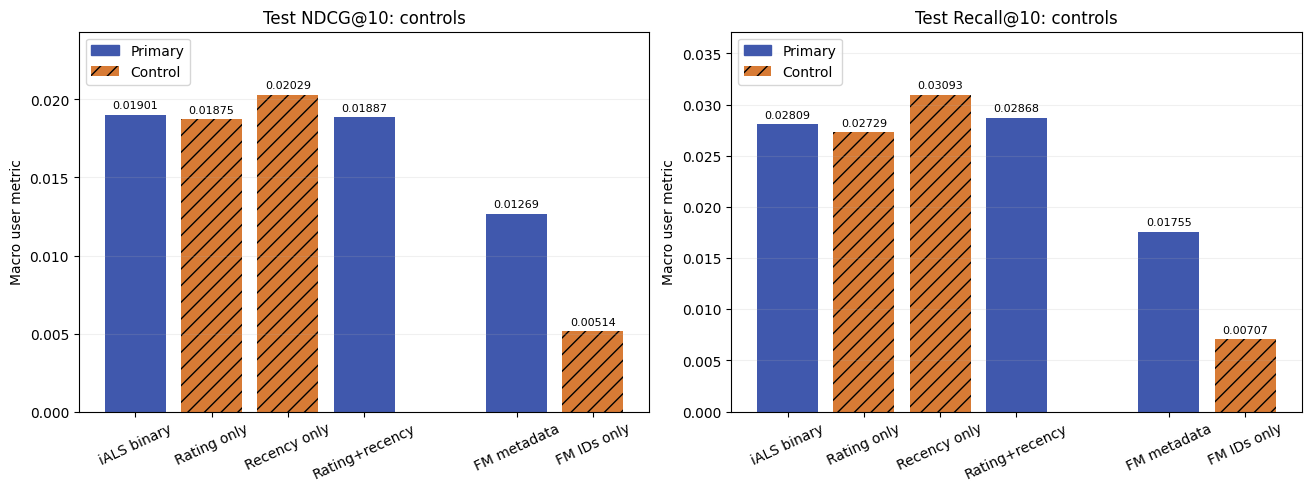

In [81]:
from matplotlib.patches import Patch

final_target_names = final_run["final_plan"]["target_ablations"]
final_meta_names = final_run["final_plan"]["metadata_ablation"]
fm_final_details = final_run["model_details"][final_meta_names["with_metadata"]]["training_details"]
fm_ids_details = final_run["model_details"][final_meta_names["IDs_only"]]["training_details"]
assert fm_final_details["examples_sha256"] == fm_ids_details["examples_sha256"]
assert fm_final_details["epochs_trained"] == fm_ids_details["epochs_trained"]
for experiment in set(final_target_names.values()):
    details = final_run["model_details"][experiment]["training_details"]
    assert details["observed_pattern_sha256"] == final_run["model_details"]["ials"]["training_details"]["observed_pattern_sha256"]
    if final_run["model_details"][experiment]["model_family"] == "custom_ials":
        assert details["target_reference_cutoff_utc"] == config["split"]["test_start_utc"]

control_names = [final_target_names[key] for key in ("binary", "rating_only", "recency_only", "rating_and_recency")]
control_names += [final_meta_names["with_metadata"], final_meta_names["IDs_only"]]
control_labels = ["iALS binary", "Rating only", "Recency only", "Rating+recency", "FM metadata", "FM IDs only"]
control_rows = final_metrics.set_index("model").loc[control_names]
positions = np.array([0, 1, 2, 3, 5, 6])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for ax, metric, title in zip(axes, ("test_ndcg_at_10", "test_recall_at_10"), ("Test NDCG@10: controls", "Test Recall@10: controls")):
    colors = ["#4058AD" if role == "primary" else "#D87B35" for role in control_rows.role]
    bars = ax.bar(positions, control_rows[metric], color=colors)
    for bar, role in zip(bars, control_rows.role):
        if role == "control": bar.set_hatch("//")
    ax.set(xticks=positions, xticklabels=control_labels, title=title, ylabel="Macro user metric")
    ax.tick_params(axis="x", labelrotation=25)
    ax.bar_label(bars, fmt="%.5f", padding=3, fontsize=8)
    ax.set_ylim(0, control_rows[metric].max() * 1.2)
    ax.grid(axis="y", alpha=.18)
    ax.legend(handles=[Patch(color="#4058AD", label="Primary"), Patch(facecolor="#D87B35", hatch="//", label="Control")], loc="upper left")
fig.savefig(PROJECT_ROOT / "results/figures/13_final_test_controls.png", dpi=140, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)

### Парные интервалы

Разности рассчитаны по одним и тем же 2614 test-пользователям. Парный bootstrap: 2000 выборок пользователей с возвращением, seed=42, 95% percentile-интервалы. Положительная разность `left−right` означает преимущество левой модели. Интервалы не учитывают новое обучение, другой период и множественные сравнения.

,comparison,left_model,right_model,metric,delta,ci_lower,ci_upper,ci_excludes_zero
0,custom_vs_binary,custom_ials,ials,ndcg@10,-0.000136,-0.004133,0.003761,False
1,custom_vs_binary,custom_ials,ials,recall@10,0.000599,-0.005345,0.006476,False
2,fm_metadata_vs_ids,fm,fm_ids_only,ndcg@10,0.007546,0.004254,0.011236,True
3,fm_metadata_vs_ids,fm,fm_ids_only,recall@10,0.010475,0.005891,0.015433,True
4,rating_only_vs_binary,custom_ials_rating_only,ials,ndcg@10,-0.000263,-0.001614,0.001165,False
5,rating_only_vs_binary,custom_ials_rating_only,ials,recall@10,-0.000800,-0.003342,0.001717,False
6,recency_only_vs_binary,custom_ials_recency_only,ials,ndcg@10,0.001279,-0.002509,0.005225,False
7,recency_only_vs_binary,custom_ials_recency_only,ials,recall@10,0.002846,-0.003367,0.009328,False
8,combined_vs_recency,custom_ials,custom_ials_recency_only,ndcg@10,-0.001415,-0.003098,0.000137,False
9,combined_vs_recency,custom_ials,custom_ials_recency_only,recall@10,-0.002247,-0.005151,0.000547,False


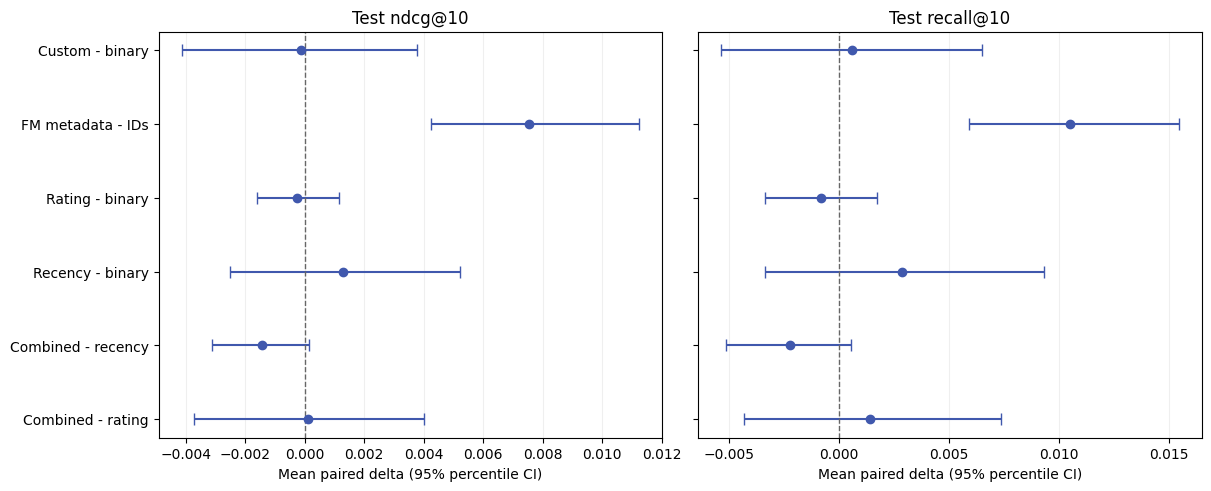

In [82]:
paired_test = final_run["paired_comparisons"]
assert len(paired_test) == 12
assert paired_test.n_users.eq(test_report["n_evaluation_users"]).all()
assert paired_test.resamples.eq(config["controls"]["paired_bootstrap_resamples"]).all()
display(paired_test[["comparison", "left_model", "right_model", "metric", "delta", "ci_lower", "ci_upper", "ci_excludes_zero"]].round(6))
pair_labels = {
    "custom_vs_binary": "Custom - binary", "fm_metadata_vs_ids": "FM metadata - IDs",
    "rating_only_vs_binary": "Rating - binary", "recency_only_vs_binary": "Recency - binary",
    "combined_vs_recency": "Combined - recency", "combined_vs_rating": "Combined - rating",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout="constrained")
for ax, metric in zip(axes, ("ndcg@10", "recall@10")):
    rows = paired_test.loc[paired_test.metric.eq(metric)].set_index("comparison").loc[list(pair_labels)]
    values = rows.delta.to_numpy()
    errors = np.vstack((np.maximum(0, values - rows.ci_lower.to_numpy()), np.maximum(0, rows.ci_upper.to_numpy() - values)))
    ax.errorbar(values, np.arange(len(rows)), xerr=errors, fmt="o", color="#4058AD", capsize=4)
    ax.axvline(0, color="#666666", linestyle="--", linewidth=1)
    ax.set(yticks=np.arange(len(rows)), yticklabels=list(pair_labels.values()),
           xlabel="Mean paired delta (95% percentile CI)", title=f"Test {metric}")
    ax.grid(axis="x", alpha=.2)
axes[0].invert_yaxis()
fig.savefig(PROJECT_ROOT / "results/figures/14_paired_test_deltas.png", dpi=140, bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)

Итоговые метрики — `results/final_metrics.csv`, все парные разности — `results/paired_test_comparisons.csv`. Индивидуальные рекомендации и веса в Git не сохраняются.

<a id="conclusions"></a>

## 6. Выводы

Числа ниже берутся из таблиц текущего прогона. Копия выводов сохраняется в [`results/conclusions.md`](results/conclusions.md).

In [83]:
from IPython.display import Markdown, display
from conclusions import build_conclusions, save_conclusions

conclusion_text = build_conclusions(
    final_metrics, search_trials, paired_test, search_selected, fm_search_epochs,
    final_run, test_report, split_summary, config,
)
conclusion_path = save_conclusions(PROJECT_ROOT / "results", conclusion_text)
display(Markdown(conclusion_text))

### Качество моделей

Среди пяти основных методов EASE получил на test наибольшие NDCG@10 = **0,01992** и Recall@10 = **0,02902**. Разница NDCG с iALS — 0,000910; парный интервал для этой пары не считался. Контроль **только с давностью** дал 0,02029 / 0,03093, но он не участвовал в выборе основной пятой модели. [Таблица](results/final_metrics.csv), [график](results/figures/12_final_test_metrics.png).

### Выбор параметров

На validation выбраны kNN с k=200 и shrinkage=10 (NDCG 0,01646), iALS с rank=128 и 20 итерациями (0,02002), EASE с lambda=100 (0,01599), FM с rank=16 и четырьмя отрицательными примерами (0,01843) и custom iALS с gamma=1, h=180 дней (0,02240). Для FM лучшая эпоха — 8; обучение остановилось на 11-й, затем лучшие веса восстановлены.

Всего проверены 12 kNN, 12 iALS, 4 EASE, 12 FM и 6 custom-конфигураций. Бюджеты поиска различались, поэтому сравнение ограничено выбранными попытками. На validation лидировал custom iALS, на test — EASE; test для повторного подбора не использовался. [Журнал](results/validation_trials.csv), [эпохи FM](results/fm_validation_epochs.csv), [выбранные настройки](results/best_params.json).

### Исторические признаки FM

При одинаковых примерах, seed и числе эпох FM с историческими признаками улучшила NDCG@10 относительно версии только с ID на **0,007546** (95% CI [0,004254; 0,011236]), Recall@10 — на **0,010475** (CI [0,005891; 0,015433]). Оба интервала исключают ноль. Это эффект внутри выбранной FM на данном test; по абсолютному качеству она уступила другим основным методам. [Парные сравнения](results/paired_test_comparisons.csv).

### Новый таргет iALS

Разность custom iALS и бинарного iALS: NDCG@10 **-0,000136**, CI [-0,004133; 0,003761]; Recall@10 **0,000599**, CI [-0,005345; 0,006476]. Оба интервала включают ноль: улучшение не подтвердилось. В контролях одна сила оценки дала -0,000263 NDCG, одна давность — 0,001279. Сочетание уступило одной давности на 0,001415 NDCG, но его CI также включает ноль. Во всех вариантах одинаковы структурные параметры и confidence; меняется только таргет. [Контроли](results/figures/13_final_test_controls.png), [интервалы](results/paired_test_comparisons.csv).

### Время и память

Для 2 614 test-пользователей EASE обучался 98,72 с, выдавал top-10 за 18,86 с и использовал до 2,386 GiB. Item-kNN обучался 1,33 с при пике 0,361 GiB. Это измерения одного CPU-прогона; пик включает данные и библиотеки, а не только веса. [Полная таблица](results/final_metrics.csv).

### Ограничения

5-core отбирает активных пользователей и товары; отзывы не равны прослушиваниям, а отсутствие отзыва не означает отрицательный интерес. Семплированные отрицательные пары FM могут быть будущими положительными. Из-за холодного старта исключены 5 322 из 13 760 положительных test-событий (38,68%). Результаты относятся к одному временному разбиению и seed=42; bootstrap пользователей не учитывает повторное обучение и не скорректирован за множественные сравнения. [Покрытие test](results/evaluation_test_summary.json), [EDA](results/eda_summary.json).
